![Banner](../../../../Images/Banner/05_geostat/09_capstones.png)

# Cadmium in the Soils of the Conterminous USA

**A geostatistical capstone: nested variograms, factorial kriging and Bayesian transformed kriging**

This is Capstone 7 of the geostatistics module (Part 9). It maps cadmium (Cd) in the A horizon of soils across the conterminous United States and asks two questions that a single kriged map cannot answer: at which spatial scales does Cd vary, and how certain is the map where it matters, near an agricultural screening value?

**Dataset:** USGS soil geochemical survey of the conterminous USA, 4,857 sites sampled 2007 to 2011, A horizon (`Data/00_shared/data_geostatistics/USA_Geochemical/usa_geochemical.csv`), and state boundaries (`Data/00_shared/data_geostatistics/US_STATE.shp`).

**Target:** Cadmium in the A horizon (`A_Cd`, mg/kg)

**Library:** `geolattice.geostatistics`

## Overview

Cadmium in soil comes from two broad sources. Geogenic Cd comes from the parent material, for example black shales and some carbonate rocks, and it is often associated with zinc. Anthropogenic Cd comes from phosphate fertilizers, sewage sludge, mining and smelting, and atmospheric deposition. The two sources act at different spatial scales: bedrock geology varies over hundreds of kilometres, while fertilizer use and point sources vary over much shorter distances. A **nested variogram** describes how variance builds up with distance as a sum of structures, and **factorial kriging** maps each structure separately, so each scale can be related to its likely sources.

The second question is about uncertainty. The data are skewed, censored and reported to only one decimal place. **Bayesian transformed kriging** (BTK) estimates the Box-Cox transformation together with the covariance parameters and integrates over their uncertainty, so its exceedance probabilities do not depend on a log transform chosen in advance.

### Objectives

| Objective | Question | Sections |
|---|---|---|
| 1. Prepare the data | How should censored and coarsely reported values be handled? | 1 and 2 |
| 2. Describe the data | How does Cd differ by land cover and region, and which elements travel with it? | 3 |
| 3. Model the scales of variation | How many structures does the variogram need, and what share of the variance does each carry? | 4 |
| 4. Map the components | What do the local, regional and continental components look like, and how do they relate to Zn, P and land cover? | 5 |
| 5. Quantify uncertainty | What are the posterior Box-Cox parameter, the median map and P(Cd > 0.48 mg/kg)? | 6 |
| 6. Validate | Which method predicts new areas best, and are its intervals honest? | 7 |
| 7. Report | Which regions and states have the largest area above the screening value? | 8 |

### Screening value

The probability maps use **0.48 mg/kg** as the agricultural soil screening value, as specified for this capstone. For context, the U.S. EPA ecological soil screening levels (Eco-SSLs, 2005) for Cd are 0.36 mg/kg for mammalian wildlife and 0.77 mg/kg for avian wildlife. Section 8 reports all three. Because Cd is reported in steps of 0.1 mg/kg, "above 0.48" means a reported value of 0.5 or more.

## API overview

```
- geopandas                          -> projection to EPSG:5070, 10 km grid, state and region join
- fit_nested_variogram               -> nugget + 1, 2 or 3 spherical structures
- FactorialKriging.extract           -> total (ordinary kriging) and each structure separately
- BayesianTransformedKriging         -> posterior of Box-Cox lambda, range and nugget ratio;
                                        posterior predictive draws on the data scale
- functions defined here             -> regression on order statistics (ROS), directional variograms,
                                        nested fit with fixed ranges, CRPS, blocked cross-validation
```

`BayesianTransformedKriging` is a global Gaussian-process model. Its memory grows with the square of the number of sites times the size of the parameter grid, and a fit on 1,000 sites exceeded the available memory during development. The sites are therefore split into disjoint random partitions of about 800, each partition is fitted separately, and the posterior predictive draws of all partitions are pooled. Every site is used exactly once.

## Setup

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import sys, time, warnings
warnings.filterwarnings("ignore")
# Keep TensorFlow out of this process (optional regression-kriging backends).
sys.modules.setdefault("tensorflow", None)

# Nested variograms, factorial kriging, and Bayesian transformed kriging.
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from scipy import stats
from scipy.optimize import nnls
from scipy.spatial.distance import pdist
from scipy.stats import norm
from sklearn.metrics import roc_auc_score, brier_score_loss

import geolattice.geostatistics as gstat
from geolattice.geostatistics import fit_nested_variogram, FactorialKriging, BayesianTransformedKriging
from geolattice.geostatistics.utils.backend import cupy_gpu_usable

# Plot defaults. SEED fixes the site partitions and the blocked cross-validation.
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_colwidth", None)
SEED = 42

# cupy_gpu_usable() runs a real kernel, so an installed but unusable CuPy stays on CPU.
USE_GPU = cupy_gpu_usable()
print("geolattice.geostatistics :", gstat.__version__)
print("Backend             :", "GPU (CuPy)" if USE_GPU else "CPU (NumPy)")

THRESHOLD = 0.48                   # mg/kg, agricultural screening value used for the probability maps
ECO_SSL = {"mammalian": 0.36, "avian": 0.77}   # mg/kg, U.S. EPA Eco-SSLs for Cd (2005)
DL = 0.1                           # mg/kg, reporting limit of A_Cd
GRID_KM = 10                       # prediction grid spacing (km)
N_PARTS = 6                       # disjoint site partitions for Bayesian transformed kriging
N_DRAWS = 250                     # posterior predictive draws per partition
FK_NEIGHBORS = 64                  # kriging neighbourhood for the total (ordinary kriging) on the 10 km grid
FACTOR_NEIGHBORS = 300             # larger neighbourhood for the factor maps
FACTOR_GRID_KM = 50                # the factors vary over 200 km or more, so a 50 km grid is enough
CHUNK = 4000                       # grid nodes per prediction batch

geolattice.geostatistics : 0.3.44
Backend             : GPU (CuPy)


## Data

Each record holds the site coordinates, the sampled depth of the A horizon, two land-cover classes (NLCD 1992) and the concentrations of 45 elements. Values below the reporting limit are stored as text such as `<0.1`. Sites are joined to their state and Census region by location, and projected to the USA Contiguous Albers Equal Area projection (EPSG:5070), in kilometres.

In [2]:
# Walk up from the working directory until the USGS geochemical table is found.
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "00_shared" / "data_geostatistics" / "USA_Geochemical" / "usa_geochemical.csv").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError(
            "Could not find Data/00_shared/data_geostatistics/USA_Geochemical/usa_geochemical.csv. "
            "Run this notebook from the GeoLattice repository."
        )
    ROOT = ROOT.parent
DATA = ROOT / "Data" / "00_shared" / "data_geostatistics"

# Site chemistry, the element metadata, and state polygons in contiguous Albers metres.
raw = pd.read_csv(DATA / "USA_Geochemical" / "usa_geochemical.csv")
meta = pd.read_csv(DATA / "USA_Geochemical" / "usa_geochemical_meta_data.csv")
states = gpd.read_file(DATA / "US_STATE.shp").to_crs(5070)

def parse_element(series):
    # Returns (value, censored flag). '<DL' -> value = DL with flag True; 'N.D.' and blanks -> NaN.
    txt = series.astype(str).str.strip()
    cens = txt.str.startswith("<")
    val = pd.to_numeric(txt.str.replace("<", "", regex=False).str.strip(), errors="coerce")
    return val, cens

cd_val, cd_cens = parse_element(raw["A_Cd"])

def depth_bottom(txt):
    # Lower depth (cm) for entries of the form 'a-b' with numbers; other entries (spreadsheet dates, 'N.S.') -> NaN
    p = str(txt).split("-")
    try:
        return float(p[1]) if len(p) == 2 and float(p[0]) <= float(p[1]) else np.nan
    except ValueError:
        return np.nan

# Project each site to EPSG:5070 and store coordinates in kilometres.
sites = gpd.GeoDataFrame(raw[["SiteID", "StateID", "LandCover1", "A_Depth", "CollDate"]].copy(),
                         geometry=gpd.points_from_xy(raw["Longitude"], raw["Latitude"]), crs=4326).to_crs(5070)
sites["Cd_raw"], sites["Cd_censored"] = cd_val, cd_cens
sites["depth_cm"] = raw["A_Depth"].map(depth_bottom)
sites["x"], sites["y"] = sites.geometry.x / 1000, sites.geometry.y / 1000
sites = gpd.sjoin(sites, states[["STATE", "REGION", "DIVISION", "geometry"]], how="left", predicate="within").drop(columns="index_right")
sites = sites[~sites.index.duplicated()]          # a site on a shared border can match two states
missing_state = sites["STATE"].isna()
if missing_state.any():   # coastal sites just outside the generalized boundaries -> nearest state
    near = gpd.sjoin_nearest(sites.loc[missing_state, ["geometry"]], states[["STATE", "REGION", "DIVISION", "geometry"]], how="left")
    near = near[~near.index.duplicated()]
    sites.loc[missing_state, ["STATE", "REGION", "DIVISION"]] = near[["STATE", "REGION", "DIVISION"]].to_numpy()

# Sample size, censoring of A_Cd, and whether the A-horizon depth can be read.
print(f"Sites: {len(sites):,}   states: {sites['STATE'].nunique()}   sampled {sites['CollDate'].str[-4:].min()} to {sites['CollDate'].str[-4:].max()}")
print(f"A_Cd: {cd_cens.sum():,} values reported as <{DL} ({100 * cd_cens.mean():.1f}%), {cd_val.isna().sum()} missing")
print(f"A-horizon depth readable for {sites['depth_cm'].notna().sum():,} sites; median lower depth {sites['depth_cm'].median():.0f} cm, "
      f"range {sites['depth_cm'].min():.1f} to {sites['depth_cm'].max():.0f} cm")
display(sites["LandCover1"].value_counts().rename("sites").to_frame().T)

Sites: 4,857   states: 48   sampled 2007 to 2011
A_Cd: 1,146 values reported as <0.1 (23.6%), 44 missing
A-horizon depth readable for 4,587 sites; median lower depth 15 cm, range 0.5 to 100 cm


LandCover1,Planted/Cultivated,Forested Upland,Shrubland,Herbaceous Upland,Developed,Barren,Non-Natural Woody
sites,1556,1252,945,815,209,68,12


## Censored and coarsely reported values

Two properties of the Cd data need a decision before any modelling.

- **Censoring.** About a quarter of the sites are below the reporting limit of 0.1 mg/kg. Three treatments are compared: substitution of half the limit (DL/2), substitution of DL/√2, and regression on order statistics (ROS), which fits a lognormal distribution to the detected values and imputes the censored ones from its lower tail.
- **Discretization.** Detected values are reported in steps of 0.1 mg/kg, so most sites share one of five values (0.1 to 0.5). The data are effectively ordinal at the low end. This matters for the variogram, which sees many zero differences, and for the threshold of 0.48 mg/kg, which falls between two reported values.

In [3]:
# Detected values only, to show how coarsely Cd is reported.
detected = sites.loc[sites["Cd_raw"].notna() & ~sites["Cd_censored"], "Cd_raw"]
print("Most frequent reported values (mg/kg):")
display(raw["A_Cd"].astype(str).str.strip().value_counts().head(8).rename("sites").to_frame().T)

def ros_impute(values, censored, dl, seed=SEED):
    # Regression on order statistics for a single detection limit (Helsel, 2012).
    # Censored values occupy the lowest plotting positions; a line is fitted to log(detected)
    # against normal quantiles of their positions, and censored values are imputed from the line
    # at the lower positions and assigned to the censored sites at random.
    v = np.asarray(values, float)
    c = np.asarray(censored, bool)
    n, nc = len(v), int(c.sum())
    pp = (np.arange(1, n + 1) - 0.375) / (n + 0.25)          # Blom plotting positions
    q = norm.ppf(pp)
    det_sorted = np.sort(np.log(v[~c]))
    slope, intercept, *_ = stats.linregress(q[nc:], det_sorted)
    imputed = np.exp(intercept + slope * q[:nc])
    imputed = np.minimum(imputed, dl)
    out = v.copy()
    out[np.flatnonzero(c)] = np.random.default_rng(seed).permutation(imputed)
    return out, (intercept, slope)

# Three substitutions for values reported as below 0.1 mg/kg.
ok_val = sites["Cd_raw"].notna().to_numpy()
v_obs = sites.loc[ok_val, "Cd_raw"].to_numpy(float)
c_obs = sites.loc[ok_val, "Cd_censored"].to_numpy(bool)
treat = {"DL/2": np.where(c_obs, DL / 2, v_obs), "DL/sqrt(2)": np.where(c_obs, DL / np.sqrt(2), v_obs)}
treat["ROS"], ros_fit = ros_impute(v_obs, c_obs, DL)

# Mean, skewness of log Cd, and the share of sites above each screening value.
rows = []
for name, v in treat.items():
    lv = np.log(v)
    rows.append({"treatment": name, "mean": v.mean(), "median": np.median(v), "geometric_mean": np.exp(lv.mean()),
                 "SD_log": lv.std(), "skew_log": stats.skew(lv), "pct_above_0.48": 100 * np.mean(v > THRESHOLD),
                 "pct_above_0.36": 100 * np.mean(v > ECO_SSL["mammalian"]), "pct_above_0.77": 100 * np.mean(v > ECO_SSL["avian"])})
cens_tbl = pd.DataFrame(rows).set_index("treatment")
display(cens_tbl.round(3))
print(f"ROS lognormal fit to detected values: log Cd = {ros_fit[0]:.2f} + {ros_fit[1]:.2f} z;  "
      f"imputed censored values range {treat['ROS'][c_obs].min():.3f} to {treat['ROS'][c_obs].max():.3f} mg/kg")

# Working data: DL/2 substitution (Section 4 checks the sensitivity of the variogram)
data = sites.loc[ok_val].reset_index(drop=True)
data["Cd"] = treat["DL/2"]
# Log Cd is the variable carried into the variogram and into factorial kriging.
data["logCd"] = np.log(data["Cd"])
xy = data[["x", "y"]].to_numpy(float)
z = data["logCd"].to_numpy(float)
cd = data["Cd"].to_numpy(float)
print(f"Working data: {len(data):,} sites with Cd")

Most frequent reported values (mg/kg):


A_Cd,0.2,<0.1,0.3,0.1,0.4,0.5,0.6,0.7
sites,1168,1146,823,733,427,188,93,60


,mean,median,geometric_mean,SD_log,skew_log,pct_above_0.48,pct_above_0.36,pct_above_0.77
treatment,,,,,,,,
DL/2,0.264,0.2,0.169,0.883,0.184,10.721,19.593,3.636
DL/sqrt(2),0.269,0.2,0.184,0.775,0.539,10.721,19.593,3.636
ROS,0.267,0.2,0.176,0.853,0.080,10.721,19.593,3.636


ROS lognormal fit to detected values: log Cd = -1.74 + 0.84 z;  imputed censored values range 0.008 to 0.097 mg/kg
Working data: 4,813 sites with Cd


**Reading the results.** The treatment of the censored values barely changes the summaries that matter here. The median (0.2 mg/kg), the share of sites above 0.48 mg/kg (10.7%) and the shares above the two Eco-SSLs (19.6% above 0.36 and 3.6% above 0.77 mg/kg) are identical under all three, because every censored value lies below every threshold. The treatments differ in the lower tail. DL/√2 gives a higher geometric mean and a smaller spread of log Cd, and ROS imputes values between 0.008 and 0.097 mg/kg. These differences enter the variogram (Section 4), not the exceedance counts.

DL/2 is used as the working treatment. It keeps the 0.1 mg/kg step between censored and detected values, and the ROS fit to the detected values (log Cd = −1.74 + 0.84 z) agrees with it in the middle of the distribution.

## Exploratory analysis

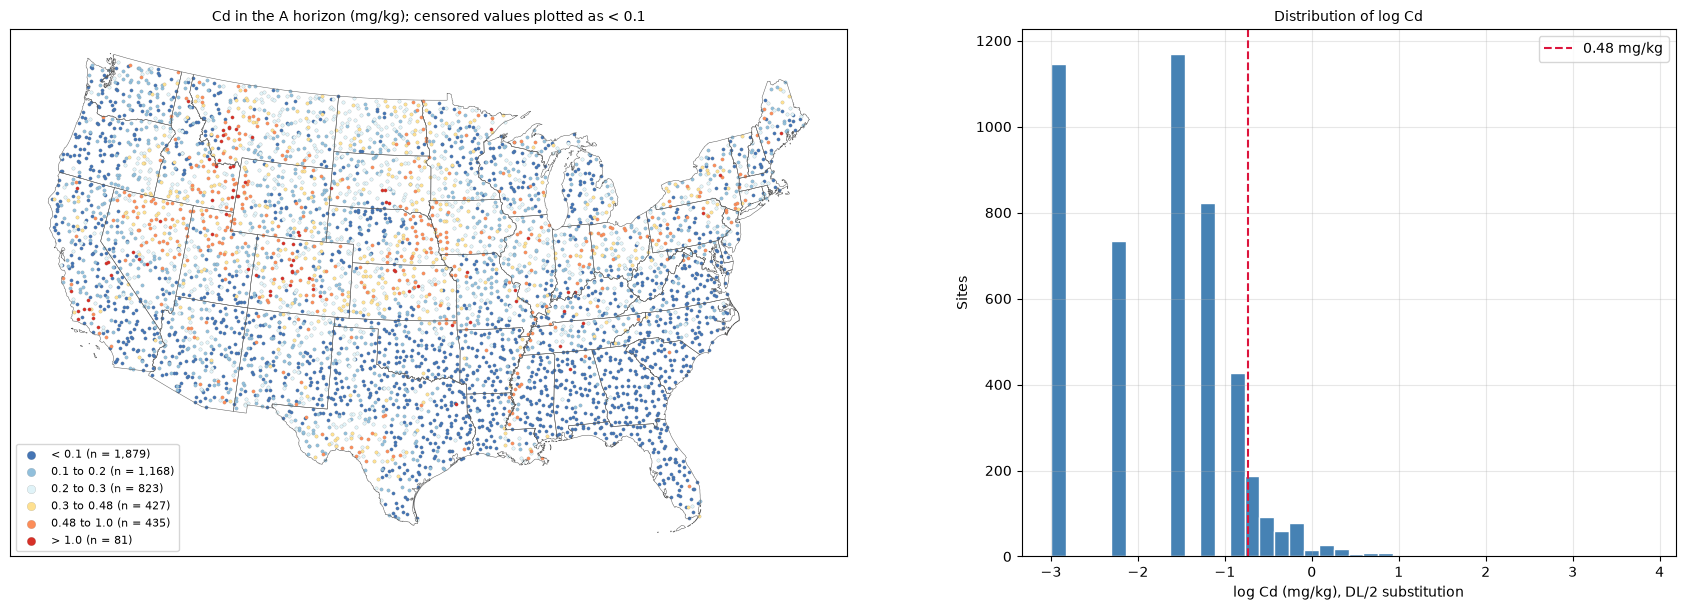

,sites,median,geometric_mean,pct_censored,pct_above_0.48,max
LandCover1,,,,,,
Shrubland,936,0.20,0.204,14.423,14.316,16.1
Herbaceous Upland,804,0.20,0.195,15.050,8.831,46.6
Planted/Cultivated,1545,0.20,0.167,25.566,10.097,3.2
Forested Upland,1241,0.20,0.149,29.734,10.798,5.0
Barren,68,0.15,0.134,27.941,5.882,0.9
Non-Natural Woody,12,0.15,0.113,41.667,0.000,0.3
Developed,207,0.10,0.111,49.275,8.213,1.4


,sites,median,geometric_mean,pct_censored,pct_above_0.48,max
REGION,,,,,,
Midwest,1233,0.30,0.231,8.678,12.733,3.2
Northeast,260,0.20,0.207,12.692,14.615,5.0
West,1903,0.20,0.203,14.136,13.768,46.6
South,1417,0.05,0.098,52.011,4.164,2.2


In [4]:
# State outlines, equal aspect, and no axes, shared by the point maps and the grid maps.
def plot_states(ax, title=None):
    states.boundary.plot(ax=ax, color="0.35", linewidth=0.35)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.grid(False)
    if title:
        ax.set_title(title, fontsize=10)

# Class breaks at the reporting limit, at 0.48 mg/kg, and at 1 mg/kg.
CLASS_EDGES = [0, 0.1, 0.2, 0.3, THRESHOLD, 1.0, np.inf]
CLASS_LABELS = ["< 0.1", "0.1 to 0.2", "0.2 to 0.3", "0.3 to 0.48", "0.48 to 1.0", "> 1.0"]
CLASS_COLORS = ["#4575b4", "#91bfdb", "#e0f3f8", "#fee090", "#fc8d59", "#d73027"]

# Point map of Cd and the histogram of log Cd. Censored sites fall in the lowest class.
fig, axes = plt.subplots(1, 2, figsize=(18, 6.2), gridspec_kw={"width_ratios": [1.6, 1]})
cls = np.digitize(cd, CLASS_EDGES[1:-1], right=True)
for k, (lab, col) in enumerate(zip(CLASS_LABELS, CLASS_COLORS)):
    m = cls == k
    axes[0].scatter(xy[m, 0] * 1000, xy[m, 1] * 1000, s=6, c=col, edgecolors="0.4", linewidths=0.1, label=f"{lab} (n = {m.sum():,})")
plot_states(axes[0], "Cd in the A horizon (mg/kg); censored values plotted as < 0.1")
axes[0].legend(loc="lower left", fontsize=8, markerscale=2.5)
axes[1].hist(z, bins=40, color="steelblue", edgecolor="white")
axes[1].axvline(np.log(THRESHOLD), color="crimson", ls="--", label=f"{THRESHOLD} mg/kg")
axes[1].set_xlabel("log Cd (mg/kg), DL/2 substitution")
axes[1].set_ylabel("Sites")
axes[1].set_title("Distribution of log Cd", fontsize=10)
axes[1].legend()
plt.tight_layout()
plt.show()

# Median, geometric mean, censoring, and exceedance rate by land cover and by Census region.
def group_summary(by):
    g = data.groupby(by)["Cd"]
    return pd.DataFrame({"sites": g.size(), "median": g.median(), "geometric_mean": g.apply(lambda s: np.exp(np.log(s).mean())),
                         "pct_censored": data.groupby(by)["Cd_censored"].mean() * 100,
                         "pct_above_0.48": g.apply(lambda s: 100 * np.mean(s > THRESHOLD)), "max": g.max()}).sort_values("geometric_mean", ascending=False)

display(group_summary("LandCover1").round(3))
display(group_summary("REGION").round(3))

In [5]:
# Companion elements. A value below its reporting limit is replaced by half that limit before the log.
ELEMENTS = ["A_Zn", "A_Pb", "A_Cu", "A_Mo", "A_Tl", "A_P", "A_S", "A_Se", "A_C_Org", "A_Ca", "A_Fe", "A_Al"]
raw_ok = raw.loc[ok_val].reset_index(drop=True)
logs = {}
for e in ELEMENTS:
    v, c = parse_element(raw_ok[e])
    v = np.where(c, v / 2, v)
    logs[e[2:]] = np.log(np.where(v > 0, v, np.nan))
logs = pd.DataFrame(logs)
# Spearman correlation of each log concentration with log Cd.
corr = logs.apply(lambda col: pd.Series(stats.spearmanr(col, z, nan_policy="omit")[:2], index=["rho", "p"])).T
corr["n"] = logs.notna().sum()
display(corr.sort_values("rho", ascending=False).round(3).T)

# The eight highest Cd sites, with zinc, lead, molybdenum, and phosphorus.
top = data.nlargest(8, "Cd")[["STATE", "LandCover1", "Cd"]].copy()
for e in ["Zn", "Pb", "Mo", "P"]:
    top[e] = np.exp(logs.loc[top.index, e]).round(1)
print("Highest Cd values:")
display(top)

# Spearman correlation of log Cd with the depth of the A horizon.
dmask = data["depth_cm"].notna()
rho_d = stats.spearmanr(data.loc[dmask, "depth_cm"], z[dmask])
print(f"Spearman correlation of log Cd with the lower sampling depth: rho = {rho_d[0]:.2f} (p = {rho_d[1]:.1e}, n = {dmask.sum():,})")

,Zn,S,P,Mo,Tl,Cu,Pb,Ca,C_Org,Fe,Se,Al
rho,0.612,0.571,0.569,0.537,0.536,0.457,0.452,0.42,0.367,0.362,0.341,0.333
p,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.000
n,4813.000,4813.000,4813.000,4813.000,4813.000,4813.000,4813.000,4813.00,4780.000,4813.000,4813.000,4813.000


Highest Cd values:


,STATE,LandCover1,Cd,Zn,Pb,Mo,P
438,California,Herbaceous Upland,46.6,119.0,8.4,11.7,450.0
2908,Nevada,Shrubland,16.1,2130.0,2200.0,9.2,1120.0
4659,Wyoming,Shrubland,8.6,163.0,12.3,17.3,720.0
694,Colorado,Shrubland,5.1,977.0,865.0,9.4,1570.0
3495,Pennsylvania,Forested Upland,5.0,304.0,186.0,1.7,1500.0
1059,Idaho,Forested Upland,4.6,324.0,178.0,1.2,3140.0
2161,Montana,Forested Upland,4.2,178.0,45.2,2.6,2140.0
595,California,Forested Upland,3.8,406.0,24.2,5.2,660.0


Spearman correlation of log Cd with the lower sampling depth: rho = -0.15 (p = 8.1e-26, n = 4,585)


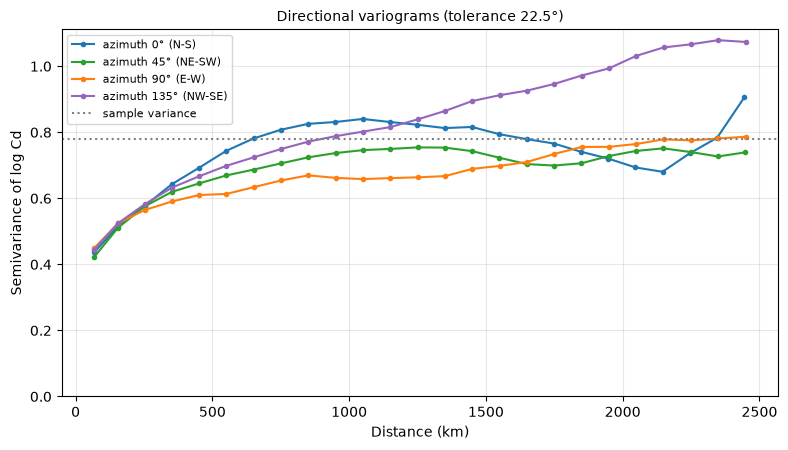

In [6]:
# Semivariance in a wedge of tol degrees around the azimuth. Bins with 30 or fewer pairs are dropped.
def directional_variogram(coords, values, azimuth, tol=22.5, maxlag=2500, n_lags=25):
    h = pdist(coords)
    i, j = np.triu_indices(len(values), 1)
    # Azimuth of each pair, folded to 0-180 because a variogram direction has no arrow.
    ang = np.degrees(np.arctan2(coords[j, 0] - coords[i, 0], coords[j, 1] - coords[i, 1])) % 180
    diff = np.abs(ang - azimuth % 180)
    keep = (np.minimum(diff, 180 - diff) <= tol) & (h < maxlag)
    sq = 0.5 * (values[i[keep]] - values[j[keep]]) ** 2
    b = np.digitize(h[keep], np.linspace(0, maxlag, n_lags + 1)) - 1
    lag = np.array([h[keep][b == k].mean() if np.sum(b == k) > 30 else np.nan for k in range(n_lags)])
    gam = np.array([sq[b == k].mean() if np.sum(b == k) > 30 else np.nan for k in range(n_lags)])
    return lag, gam

# Four directions. Similar curves mean log Cd is close to isotropic at this tolerance.
fig, ax = plt.subplots(figsize=(8, 4.6))
for az, c in zip([0, 45, 90, 135], ["tab:blue", "tab:green", "tab:orange", "tab:purple"]):
    lag, gam = directional_variogram(xy, z, az)
    ax.plot(lag, gam, "o-", ms=3, color=c, label=f"azimuth {az}° ({['N-S', 'NE-SW', 'E-W', 'NW-SE'][[0, 45, 90, 135].index(az)]})")
# Sample variance: the sill a stationary variogram would level off at.
ax.axhline(z.var(), color="0.5", ls=":", label="sample variance")
ax.set_xlabel("Distance (km)"); ax.set_ylabel("Semivariance of log Cd")
ax.set_title("Directional variograms (tolerance 22.5°)", fontsize=10)
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading the results.**

- **Regions.** The South stands out: 52% of its sites are below the reporting limit and only 4% are above 0.48 mg/kg, against 13% to 15% in the other regions. The Midwest has the highest geometric mean (0.23 mg/kg).
- **Land cover.** Shrubland and herbaceous upland, mostly in the West, have the highest geometric means. Developed land has the lowest, with half of its sites censored. Cultivated land is in the middle (geometric mean 0.17 mg/kg), so at the scale of this survey there is no general enrichment of cropland soils.
- **Associated elements.** Log Cd correlates most with Zn (ρ = 0.61), S and P (0.57), Mo and Tl (0.54), followed by Cu and Pb (0.46). This group combines chalcophile elements, which point to sulfide-bearing and black-shale parent materials, with P and organic C, which point to fertilizer and organic matter.
- **Extremes.** The highest values are mostly isolated sites. The Nevada and Colorado sites have very high Zn and Pb as well (2,130 and 977 mg/kg Zn), consistent with mineralization or mining. The California site (46.6 mg/kg) has ordinary Zn and Pb but high Mo.
- **Depth.** Cd decreases slightly with sampling depth (ρ = −0.15), as expected for an element enriched near the surface. Depth is not used as a covariate here, but it adds to the nugget.
- **Anisotropy.** The directional variograms are close to each other up to about 1,000 km. Beyond that the north-south direction rises faster, which reflects the low-Cd South. An isotropic model is used.

## Nested variogram

`fit_nested_variogram` fits a nugget plus a sum of structures to the experimental variogram by least squares:

$$
\gamma(h) = c_0 + \sum_{k=1}^{K} c_k\, g_k(h; a_k),
$$

where $g_k$ is a spherical structure with range $a_k$ and partial sill $c_k$. Models with one, two and three structures are compared. The share of the total sill carried by each structure is the "variance by scale".

,nugget,total_sill,nugget_share_pct,SSE,range_1_km,share_1_pct,range_2_km,share_2_pct,range_3_km,share_3_pct
structures,,,,,,,,,,
1,0.512,0.841,60.859,0.028,2029.522,39.141,NaN,NaN,NaN,NaN
2,0.407,1.126,36.163,0.003,637.313,21.144,7500.000,42.693,NaN,NaN
3,0.366,1.118,32.729,0.002,238.968,8.889,761.298,16.513,7500.0,41.869


Sample variance of log Cd: 0.780.  Range bound of the fit: 7500 km.


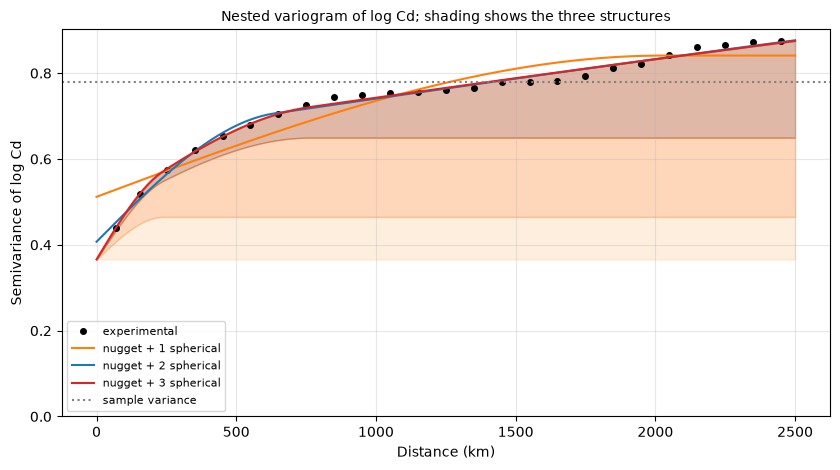

In [7]:
# Fit out to 2500 km, most of the width of the conterminous USA.
MAXLAG, N_LAGS = 2500.0, 25

# Spherical structure, equal to 1 once the distance reaches the range.
def sph(h, a):
    hr = np.minimum(np.asarray(h, float) / a, 1.0)
    return 1.5 * hr - 0.5 * hr ** 3

# Nugget plus the sum of the spherical structures.
def nested_curve(h, nugget, structs):
    return nugget + sum(s["sill"] * sph(h, s["range"]) for s in structs)

# One, two, and three structures. SSE is the lack of fit to the experimental variogram.
fits = {}
for k in (1, 2, 3):
    nug, structs, lh, lg = fit_nested_variogram(xy, z, models=("spherical",) * k, n_lags=N_LAGS, maxlag=MAXLAG)
    pred = nested_curve(lh, nug, structs)
    fits[k] = {"nugget": nug, "structs": structs, "lag_h": lh, "lag_g": lg, "SSE": float(np.sum((pred - lg) ** 2))}

# Share of the total sill carried by the nugget and by each structure.
rows = []
for k, f in fits.items():
    total = f["nugget"] + sum(s["sill"] for s in f["structs"])
    row = {"structures": k, "nugget": f["nugget"], "total_sill": total, "nugget_share_pct": 100 * f["nugget"] / total, "SSE": f["SSE"]}
    for i, s in enumerate(f["structs"], 1):
        row[f"range_{i}_km"] = s["range"]
        row[f"share_{i}_pct"] = 100 * s["sill"] / total
    rows.append(row)
nest_tbl = pd.DataFrame(rows).set_index("structures")
display(nest_tbl.round(3))
print(f"Sample variance of log Cd: {z.var():.3f}.  Range bound of the fit: {3 * MAXLAG:.0f} km.")

# Experimental variogram, the three fitted curves, and the three structures as shaded bands.
fig, ax = plt.subplots(figsize=(8.5, 4.8))
f3 = fits[3]
ax.plot(f3["lag_h"], f3["lag_g"], "ko", ms=4, label="experimental")
hh = np.linspace(0.1, MAXLAG, 300)
for k, c in zip((1, 2, 3), ["tab:orange", "tab:blue", "tab:red"]):
    ax.plot(hh, nested_curve(hh, fits[k]["nugget"], fits[k]["structs"]), color=c, label=f"nugget + {k} spherical")
cum = f3["nugget"]
for s, c in zip(f3["structs"], ["#fdd0a2", "#fd8d3c", "#a63603"]):
    ax.fill_between(hh, cum, cum + s["sill"] * sph(hh, s["range"]), color=c, alpha=0.35)
    cum = cum + s["sill"] * sph(hh, s["range"])
ax.axhline(z.var(), color="0.5", ls=":", label="sample variance")
ax.set_xlabel("Distance (km)"); ax.set_ylabel("Semivariance of log Cd")
ax.set_title("Nested variogram of log Cd; shading shows the three structures", fontsize=10)
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Sensitivity to censoring and outliers

The three-structure model is refitted with the other two censoring treatments and without the eight highest values.

In [8]:
# Three spherical structures. Shares are percentages of the nugget plus the partial sills.
def fit3(zv, coords=xy):
    nug, structs, *_ = fit_nested_variogram(coords, zv, models=("spherical",) * 3, n_lags=N_LAGS, maxlag=MAXLAG)
    total = nug + sum(s["sill"] for s in structs)
    out = {"nugget_share_pct": 100 * nug / total, "total_sill": total}
    for i, s in enumerate(structs, 1):
        out[f"range_{i}_km"], out[f"share_{i}_pct"] = s["range"], 100 * s["sill"] / total
    return out

# Same fit with the eight highest Cd values removed, in case they set the short-range sill.
no_top = ~data.index.isin(data.nlargest(8, "Cd").index)
# DL/2, the other two substitutions, and the fit without those eight sites.
sens = pd.DataFrame({
    "DL/2 (working data)": fit3(z),
    "DL/sqrt(2)": fit3(np.log(treat["DL/sqrt(2)"])),
    "ROS": fit3(np.log(treat["ROS"])),
    "DL/2 without the 8 highest values": fit3(z[no_top], xy[no_top]),
}).T
display(sens.round(2))

,nugget_share_pct,total_sill,range_1_km,share_1_pct,range_2_km,share_2_pct,range_3_km,share_3_pct
DL/2 (working data),32.73,1.12,238.97,8.89,761.30,16.51,7500.0,41.87
DL/sqrt(2),37.10,0.79,234.12,9.48,756.09,19.99,7500.0,33.43
ROS,36.32,1.02,241.94,8.29,744.20,15.47,7500.0,39.92
DL/2 without the 8 highest values,32.13,1.08,241.72,9.16,781.78,17.68,7500.0,41.04


**Reading the results.**

- **One structure is not enough.** Its residual error is about ten times that of the nested models, and it misses the shape near the origin.
- **Three structures** fit best: a nugget of 33% of the sill, a local structure of about 240 km (9%), a regional structure of about 760 km (17%) and a long structure (42%) whose range is at the bound of the fit (7,500 km). The variogram is still rising at 2,500 km, above the sample variance. The long structure is therefore a continental trend, the contrast between the low-Cd South and the rest of the country, rather than a structure with a definite range.
- **The local and regional ranges are robust.** They change by less than 5% across the censoring treatments and without the eight highest values. The nugget share moves between 32% and 37%. The share of the long structure is the least stable (33% to 42%), as expected for a trend.

A third of the variance is nugget, which combines measurement and reporting error (the 0.1 mg/kg steps), differences in sampling depth and true variation over less than the 40 km between sites. No map at this sampling density can predict the value at an individual field.

## Factorial kriging

Factorial kriging estimates each structure of the nested model as a separate map. For structure $k$ the estimate is

$$
\hat Y_k(\mathbf{u}) = \sum_{\alpha} \lambda^{(k)}_\alpha\, z(\mathbf{u}_\alpha), \qquad \sum_\alpha \lambda^{(k)}_\alpha = 0,
$$

with the covariance of structure $k$ alone on the right-hand side of the kriging system. Ordinary kriging of the total, `extract("total")`, uses the same system with the full covariance and weights summing to 1. Its estimate and variance give a lognormal kriging reference: median $e^{\hat y}$ and $P(Z > t) = 1 - \Phi\big((\ln t - \hat y)/\sigma\big)$.

Two neighbourhoods are used. The total (ordinary kriging) is computed on the 10 km grid (about 78,000 nodes) from the 64 nearest sites. A factor can only be separated from the others if the neighbourhood is large compared with its range. The 64 nearest sites reach only about 150 km, so the factor maps are computed from the 300 nearest sites (a radius of about 350 km) on a 50 km grid. The factors vary over 200 km or more, so the coarser grid loses nothing.

Even 300 sites are not enough for the third structure, whose range is at the bound of the fit. Within a 350 km window it cannot be told apart from the regional structure, so factors 2 and 3 are shown together as one "long-range" factor.

Grid: 78,079 nodes at 10 km (7.81 million km²)


Ordinary kriging of log Cd on the 10 km grid: 5 s


Factor maps on 3,126 nodes (50 km) with 300 neighbours: 0.4 min
Correlation between factor maps: local vs regional 0.66, regional vs continental 0.98


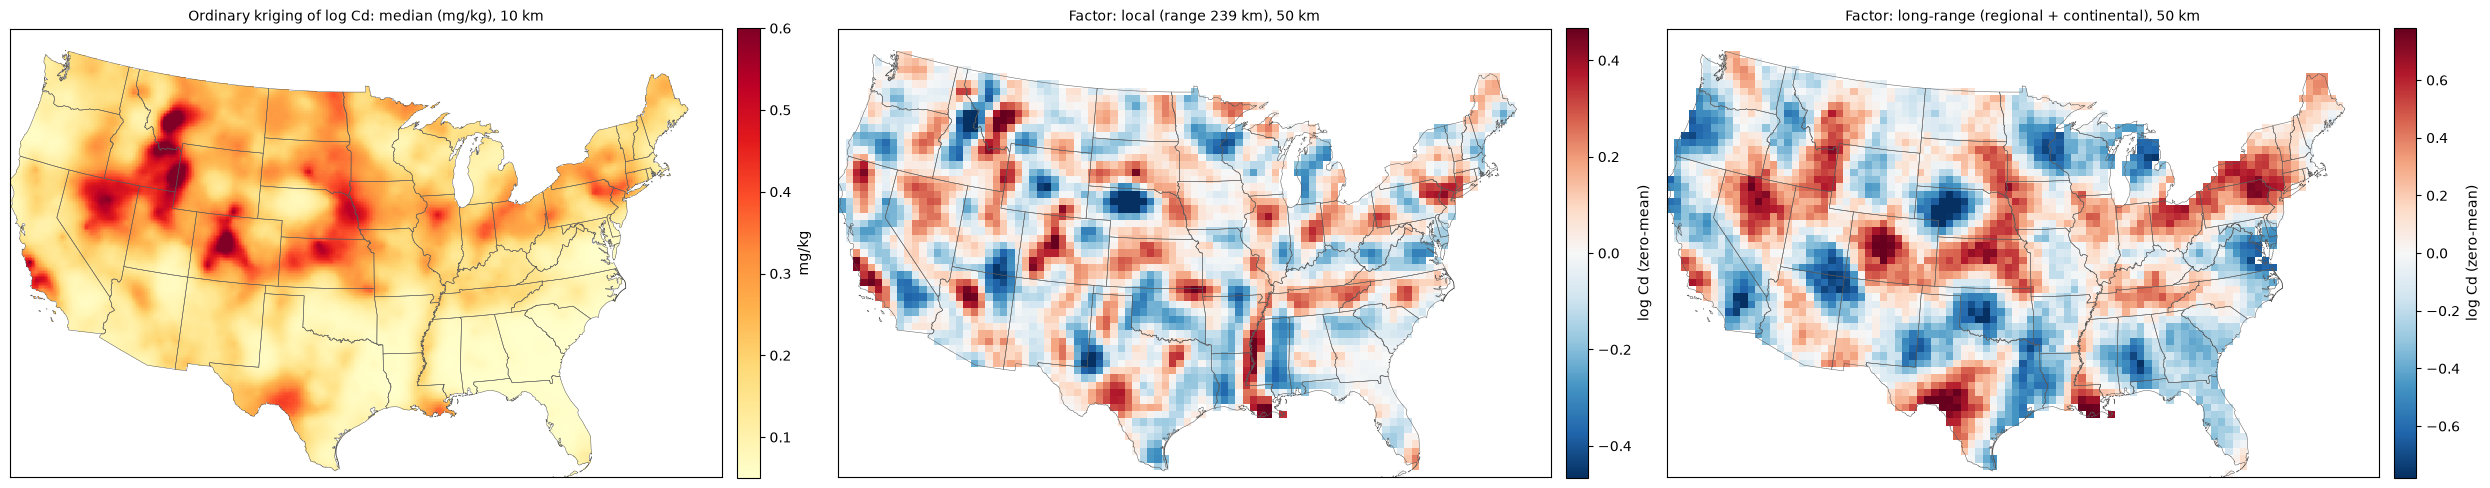

Standard deviation of each factor map (log units): {'local (range 239 km)': 0.173, 'regional (range 761 km)': 0.256, 'continental (range 7500 km)': 0.078, 'long-range (regional + continental)': 0.332}


In [9]:
# 10 km nodes, inset by half a cell, then kept only where they fall inside a state.
minx, miny, maxx, maxy = states.total_bounds
gx = np.arange(minx + GRID_KM * 500, maxx, GRID_KM * 1000)
gy = np.arange(miny + GRID_KM * 500, maxy, GRID_KM * 1000)
GX, GY = np.meshgrid(gx, gy)
cand = gpd.GeoDataFrame(geometry=gpd.points_from_xy(GX.ravel(), GY.ravel()), crs=5070)
grid = gpd.sjoin(cand, states[["STATE", "REGION", "geometry"]], how="inner", predicate="within")
grid = grid[~grid.index.duplicated()]
gxy = np.column_stack([grid.geometry.x, grid.geometry.y]) / 1000
g_col = np.searchsorted(gx / 1000, gxy[:, 0])
g_row = np.searchsorted(gy / 1000, gxy[:, 1])
CELL_KM2 = GRID_KM ** 2
print(f"Grid: {len(grid):,} nodes at {GRID_KM} km ({len(grid) * CELL_KM2 / 1e6:.2f} million km²)")

# Place node values back on the mesh for plotting.
def to_raster(values):
    r = np.full((len(gy), len(gx)), np.nan)
    r[g_row, g_col] = values
    return r

# Filled grid, state outlines, and a colour bar.
def plot_grid(ax, values, title, cmap="viridis", vmin=None, vmax=None, label="", norm_=None):
    im = ax.pcolormesh(gx, gy, to_raster(values), cmap=cmap, vmin=vmin, vmax=vmax, norm=norm_, shading="nearest")
    plot_states(ax, title)
    plt.colorbar(im, ax=ax, label=label, fraction=0.03, pad=0.02)
    return im

# Predict in batches, so the neighbourhood search stays within memory.
def fk_extract(fk, coords, factor, return_variance=False):
    parts = [fk.extract(coords[i:i + CHUNK], factor, return_variance=return_variance) for i in range(0, len(coords), CHUNK)]
    if return_variance:
        return np.concatenate([p[0] for p in parts]), np.concatenate([p[1] for p in parts])
    return np.concatenate(parts)

# Ordinary kriging of log Cd is the total factor of the three-structure model.
NUG, STRUCTS = fits[3]["nugget"], fits[3]["structs"]
fk_cd = FactorialKriging(NUG, STRUCTS, max_neighbors=FK_NEIGHBORS, use_gpu=USE_GPU).fit(xy, z)
t0 = time.perf_counter()
fk_total, fk_var = fk_extract(fk_cd, gxy, "total", return_variance=True)
fk_sd = np.sqrt(np.maximum(fk_var, 0))
print(f"Ordinary kriging of log Cd on the {GRID_KM} km grid: {time.perf_counter() - t0:.0f} s")

# Factor maps on a coarser grid with a large neighbourhood
step = int(FACTOR_GRID_KM / GRID_KM)
fmask = (g_col % step == step // 2) & (g_row % step == step // 2)
fxy = gxy[fmask]
fk_big = FactorialKriging(NUG, STRUCTS, max_neighbors=FACTOR_NEIGHBORS, use_gpu=USE_GPU).fit(xy, z)
def fk_extract_big(fk, coords, factor, chunk=300):
    return np.concatenate([fk.extract(coords[i:i + chunk], factor) for i in range(0, len(coords), chunk)])
t0 = time.perf_counter()
# Local, regional, and continental factors on the coarse grid.
components = {k: fk_extract_big(fk_big, fxy, k) for k in (1, 2, 3)}
print(f"Factor maps on {len(fxy):,} nodes ({FACTOR_GRID_KM} km) with {FACTOR_NEIGHBORS} neighbours: {(time.perf_counter() - t0) / 60:.1f} min")
print(f"Correlation between factor maps: local vs regional {np.corrcoef(components[1], components[2])[0, 1]:.2f}, "
      f"regional vs continental {np.corrcoef(components[2], components[3])[0, 1]:.2f}")
# Regional plus continental: the long-range pattern on its own.
components["long"] = components[2] + components[3]

names = {1: f"local (range {STRUCTS[0]['range']:.0f} km)", 2: f"regional (range {STRUCTS[1]['range']:.0f} km)",
         3: f"continental (range {STRUCTS[2]['range']:.0f} km)", "long": "long-range (regional + continental)"}

# One cell per factor node on the coarse grid.
def plot_coarse(ax, values, title, cmap="RdBu_r", vmin=None, vmax=None, label=""):
    r = np.full((len(gy), len(gx)), np.nan)
    r[g_row[fmask], g_col[fmask]] = values
    r = r[step // 2::step, step // 2::step]
    im = ax.pcolormesh(gx[step // 2::step], gy[step // 2::step], r, cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest")
    plot_states(ax, title)
    plt.colorbar(im, ax=ax, label=label, fraction=0.03, pad=0.02)

# Median Cd from the kriged log, beside the local factor and the long-range factor.
fig, axes = plt.subplots(1, 3, figsize=(25, 6.2))
plot_grid(axes[0], np.exp(fk_total), "Ordinary kriging of log Cd: median (mg/kg), 10 km", cmap="YlOrRd", vmin=0.05, vmax=0.6, label="mg/kg")
for ax, k in zip(axes[1:], (1, "long")):
    lim = np.nanpercentile(np.abs(components[k]), 99)
    plot_coarse(ax, components[k], f"Factor: {names[k]}, {FACTOR_GRID_KM} km", vmin=-lim, vmax=lim, label="log Cd (zero-mean)")
plt.tight_layout()
plt.show()

print("Standard deviation of each factor map (log units):", {names[k]: round(float(np.std(v)), 3) for k, v in components.items()})

### Which scale relates to which source?

Three checks connect the factors to sources.

1. **Land cover.** The factors are estimated at the sites, and their distribution is compared across land-cover classes. A fertilizer signal would raise the local factor on cultivated land.
2. **Zinc.** Geogenic Cd travels with Zn, so a strong Cd-Zn correlation at a given scale points to geology at that scale.
3. **Phosphorus.** Phosphate fertilizer adds both P and Cd, so a Cd-P correlation at the local scale on cultivated land would be consistent with fertilizer input.

For the second and third checks, log Zn and log P are given nested models with the same three ranges as Cd. Their sills, and the sills of their cross-variograms with log Cd, are refitted by least squares. For each structure $k$ the **structural correlation** $r_k = b^{(k)}_{12}/\sqrt{b^{(k)}_{11}\,b^{(k)}_{22}}$ is the correlation between the two elements at that scale alone (Goovaerts, 1997; Wackernagel, 2003). Unlike the correlation of the raw data, it can differ from scale to scale.

Factors at the 4,813 sites: 0.4 min


,local (range 239 km),long-range (regional + continental),mean_logCd,sites
Planted/Cultivated,0.010,0.001,-1.791,1545
Developed,0.009,-0.043,-2.196,207
Shrubland,0.006,0.038,-1.589,936
Herbaceous Upland,-0.002,0.013,-1.637,804
Forested Upland,-0.008,-0.058,-1.901,1241
Non-Natural Woody,-0.024,0.008,-2.177,12
Barren,-0.083,-0.234,-2.009,68


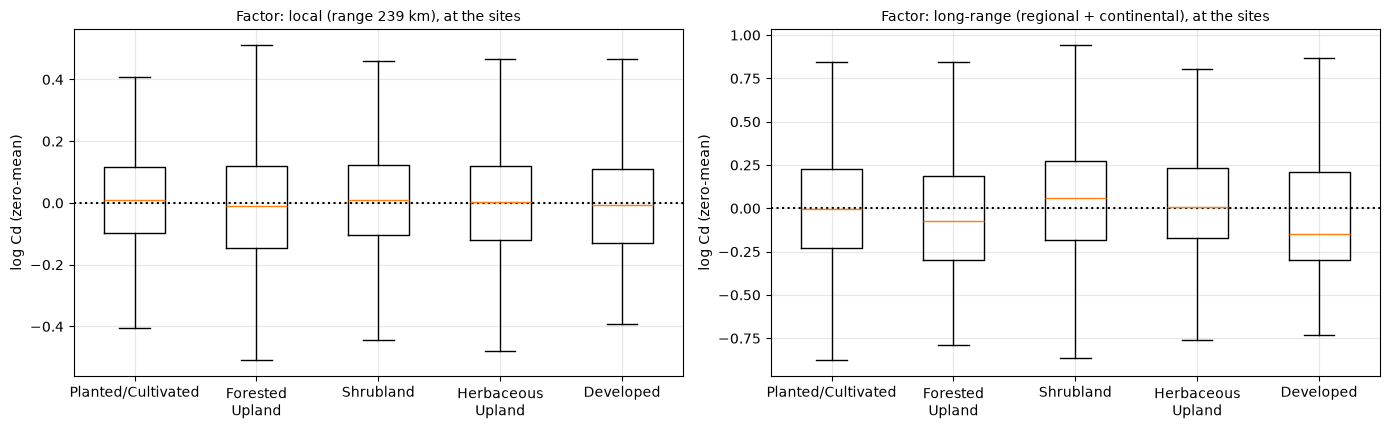

Variance by scale (% of the total sill), all three elements with the Cd ranges:


,nugget,local (range 239 km),regional (range 761 km),continental (range 7500 km)
Cd (sills refitted with the same ranges),33.1,8.7,17.1,41.1
Zn,20.2,4.0,4.8,71.0
P,23.9,3.1,7.2,65.8


Structural correlation of log Cd with log Zn and log P at each scale, b_12 / sqrt(b_11 b_22):


,nugget,local (range 239 km),regional (range 761 km),continental (range 7500 km)
Zn,0.53,0.94,0.76,0.71
P,0.42,0.64,0.96,0.65


Values outside [-1, 1] would mean that the separately fitted sill matrices are not positive semi-definite.


Correlation of the local factors of Cd and P at the sites: cultivated r = 0.59, other land cover r = 0.63


In [10]:
# Local and long-range factors at the sample sites, for the land-cover comparison.
t0 = time.perf_counter()
fac_sites = {1: fk_extract_big(fk_big, xy, 1)}
fac_sites["long"] = fk_extract_big(fk_big, xy, [2, 3])
print(f"Factors at the {len(xy):,} sites: {(time.perf_counter() - t0) / 60:.1f} min")
# Mean of each factor inside a land-cover class.
lc_tbl = pd.DataFrame({names[k]: pd.Series(v).groupby(data["LandCover1"].to_numpy()).mean() for k, v in fac_sites.items()})
lc_tbl["mean_logCd"] = pd.Series(z).groupby(data["LandCover1"].to_numpy()).mean()
lc_tbl["sites"] = data["LandCover1"].value_counts()
display(lc_tbl.sort_values(names[1], ascending=False).round(3))

# The five most common covers. Outliers are hidden so each box shows the bulk of the sites.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
lcs = data["LandCover1"].value_counts().index[:5]
for ax, k in zip(axes, (1, "long")):
    ax.boxplot([fac_sites[k][data["LandCover1"].to_numpy() == lc] for lc in lcs], tick_labels=[l.replace(" ", "\n") for l in lcs], showfliers=False)
    ax.axhline(0, color="k", ls=":")
    ax.set_title(f"Factor: {names[k]}, at the sites", fontsize=10)
    ax.set_ylabel("log Cd (zero-mean)")
plt.tight_layout()
plt.show()

# Classical variogram. Bins with 30 or fewer pairs are dropped.
def experimental_classical(coords, v, maxlag=MAXLAG, n_lags=N_LAGS):
    ok = np.isfinite(v)
    c, v = coords[ok], v[ok]
    h, sq = pdist(c), 0.5 * pdist(v[:, None]) ** 2
    b = np.digitize(h, np.linspace(0, maxlag, n_lags + 1)) - 1
    keep = [k for k in range(n_lags) if np.sum(b == k) > 30]
    return np.array([h[b == k].mean() for k in keep]), np.array([sq[b == k].mean() for k in keep]), np.array([np.sum(b == k) for k in keep])

# Refit only the sills, with the Cd ranges held fixed, by non-negative least squares.
def fit_sills_fixed_ranges(coords, v, ranges):
    lh, lg, n = experimental_classical(coords, v)
    A = np.column_stack([np.ones_like(lh)] + [sph(lh, a) for a in ranges]) * np.sqrt(n)[:, None]
    c, _ = nnls(A, lg * np.sqrt(n))
    return float(c[0]), [{"model": "spherical", "sill": float(s), "range": float(a)} for s, a in zip(c[1:], ranges)]

ranges = [s["range"] for s in STRUCTS]

# Cross-variogram of two variables on the same distance bins.
def experimental_cross(coords, u, v, maxlag=MAXLAG, n_lags=N_LAGS):
    ok = np.isfinite(u) & np.isfinite(v)
    c, u, v = coords[ok], u[ok], v[ok]
    h = pdist(c)
    i, j = np.triu_indices(len(u), 1)
    prod = 0.5 * (u[i] - u[j]) * (v[i] - v[j])
    b = np.digitize(h, np.linspace(0, maxlag, n_lags + 1)) - 1
    keep = [k for k in range(n_lags) if np.sum(b == k) > 30]
    return np.array([h[b == k].mean() for k in keep]), np.array([prod[b == k].mean() for k in keep]), np.array([np.sum(b == k) for k in keep])

# Sill coefficients of the cross-variogram. Negative values are allowed, so the fit is ordinary least squares.
def cross_sills_fixed_ranges(coords, u, v, ranges):
    lh, lg, n = experimental_cross(coords, u, v)
    A = np.column_stack([np.ones_like(lh)] + [sph(lh, a) for a in ranges]) * np.sqrt(n)[:, None]
    return np.linalg.lstsq(A, lg * np.sqrt(n), rcond=None)[0]

# Variance share of Zn and P, and their structural correlation with Cd, at the Cd ranges.
nug_cd, st_cd = fit_sills_fixed_ranges(xy, z, ranges)
b_cd = np.r_[nug_cd, [s_["sill"] for s_ in st_cd]]
scale_names = ["nugget"] + [names[k] for k in (1, 2, 3)]
rows, corr_rows = [], []
for el in ["Zn", "P"]:
    v = logs[el].to_numpy()
    nug_e, st_e = fit_sills_fixed_ranges(xy, v, ranges)
    b_e = np.r_[nug_e, [s_["sill"] for s_ in st_e]]
    b_x = cross_sills_fixed_ranges(xy, z, v, ranges)
    with np.errstate(invalid="ignore", divide="ignore"):
        r = b_x / np.sqrt(b_cd * b_e)
    rows.append(pd.Series(100 * b_e / b_e.sum(), index=scale_names, name=el))
    corr_rows.append(pd.Series(r, index=scale_names, name=el))
cd_share = pd.Series(100 * b_cd / b_cd.sum(), index=scale_names, name="Cd (sills refitted with the same ranges)")
print("Variance by scale (% of the total sill), all three elements with the Cd ranges:")
display(pd.concat([cd_share] + rows, axis=1).T.round(1))
struct_corr = pd.concat(corr_rows, axis=1).T
print("Structural correlation of log Cd with log Zn and log P at each scale, b_12 / sqrt(b_11 b_22):")
display(struct_corr.round(2))
print("Values outside [-1, 1] would mean that the separately fitted sill matrices are not positive semi-definite.")

# Local factor of phosphorus next to the local factor of Cd, on cultivated land and off it.
cult = (data["LandCover1"] == "Planted/Cultivated").to_numpy()
fk_p_sites = FactorialKriging(*fit_sills_fixed_ranges(xy, logs["P"].to_numpy(), ranges), max_neighbors=FACTOR_NEIGHBORS, use_gpu=USE_GPU)
okp = np.isfinite(logs["P"].to_numpy())
fk_p_sites.fit(xy[okp], logs["P"].to_numpy()[okp])
p_loc = fk_extract_big(fk_p_sites, xy, 1)
print(f"Correlation of the local factors of Cd and P at the sites: cultivated r = {np.corrcoef(fac_sites[1][cult], p_loc[cult])[0, 1]:.2f}, "
      f"other land cover r = {np.corrcoef(fac_sites[1][~cult], p_loc[~cult])[0, 1]:.2f}")

**Reading the results.**

- **The local factor (about 240 km)** shows isolated highs: southern Idaho and the Snake River Plain, western Colorado, central Nebraska, the lower Mississippi valley and southern California. These are features at the scale of a few counties to a state.
- **The long-range factor** shows the broad pattern: high across the northern Great Plains, the Rocky Mountain states and the northeast, low across the South and the Pacific Northwest coast.
- **Zinc shows a geogenic link at the local scale.** The structural correlation of Cd with Zn is 0.94 at the local scale, 0.76 at the regional scale and 0.71 at the continental scale. Local Cd highs coincide with Zn highs, which points to bedrock or mineralization as the cause of the local structure.
- **Phosphorus is linked at the regional scale.** The structural correlation of Cd with P is 0.64 at the local scale and 0.96 at the regional scale. The regional patterns of the two elements are almost the same. That is consistent with broad regional controls shared by both elements, such as climate, organic matter and agricultural regions, but it does not identify fertilizer as the source.
- **No land-cover signal at these scales.** The mean local factor differs by less than 0.02 log units between cultivated, shrubland, herbaceous and forested sites. The local factors of Cd and P are no more correlated on cultivated land (r = 0.59) than elsewhere (0.63). If phosphate fertilizer adds Cd, it does so at field scale, which falls into the nugget at this sampling density.

Zn, and especially P, have most of their variance in the long structure (71% and 66%), so their spatial patterns are smoother than that of Cd.

## Bayesian transformed kriging

The model (De Oliveira, Kedem and Short, 1997) assumes that a Box-Cox transform of Cd is a Gaussian random field,

$$
g_\lambda(Z) = \frac{Z^\lambda - 1}{\lambda}\ (\lambda \neq 0), \qquad g_0(Z) = \ln Z, \qquad g_\lambda(Z(\mathbf{u})) = \mu + S(\mathbf{u}) + \varepsilon(\mathbf{u}),
$$

with an exponential covariance for $S$ and a nugget $\varepsilon$. The posterior is computed over a grid of $\lambda$, range and nugget ratio, and predictions are posterior predictive draws back-transformed to mg/kg. The uncertainty in $\lambda$ and in the covariance therefore enters every map.

The sites are split into `N_PARTS` disjoint random partitions of about 800 sites. Each partition is fitted separately and `N_DRAWS` draws are taken at every grid node. Pooling the draws of all partitions gives a mixture distribution at each node. Each partition sees only a sixth of the data, so its local predictions are less precise than a fit to all sites would be. Section 7 measures what this costs.

In [11]:
# Search grid for the exponential range, the nugget ratio, and the Box-Cox lambda.
BTK_KW = dict(model="exponential", range_grid=np.geomspace(50, 3000, 12), nugget_grid=(0.25, 0.5, 1.0, 2.0),
              lambda_grid=(-0.5, -0.25, 0.0, 0.25, 0.5))
DRAW_CLIP = (1e-3, 1e3)       # mg/kg; guards against draws outside the Box-Cox domain

# Split the sites into disjoint random groups of nearly equal size.
def partitions(n, k, seed):
    return np.array_split(np.random.default_rng(seed).permutation(n), k)

def btk_ensemble(train_idx, coords_pred, n_parts=N_PARTS, n_draws=N_DRAWS, seed=SEED, keep_params=False):
    # Fit BTK on disjoint partitions of train_idx and return pooled draws (n_parts * n_draws, n_pred), float32
    draws, params = [], []
    for p, part in enumerate(partitions(len(train_idx), n_parts, seed)):
        idx = train_idx[part]
        m = BayesianTransformedKriging(**BTK_KW).fit(xy[idx], cd[idx])
        d = np.empty((n_draws, len(coords_pred)), dtype=np.float32)
        for i in range(0, len(coords_pred), CHUNK):
            d[:, i:i + CHUNK] = m.predictive_samples(coords_pred[i:i + CHUNK], n_samples=n_draws, seed=seed + p)
        draws.append(np.clip(d, *DRAW_CLIP))
        if keep_params:
            s = m.sample_parameters(2000, seed=seed + p)
            s["partition"] = p + 1
            params.append(s)
        del m
    return np.vstack(draws), (pd.concat(params, ignore_index=True) if keep_params else None)

# Fit every partition and draw predictions for the 10 km grid. Parameter draws are kept for the table.
t0 = time.perf_counter()
all_idx = np.arange(len(z))
btk_draws, btk_params = btk_ensemble(all_idx, gxy, keep_params=True)
print(f"BTK: {N_PARTS} partitions x {N_DRAWS} draws x {len(gxy):,} nodes in {(time.perf_counter() - t0) / 60:.1f} min")

# Posterior mean of lambda, and the median range and nugget ratio, one row per partition.
post = (btk_params.groupby("partition")
        .agg(lambda_mean=("lambda", "mean"), range_median_km=("range", "median"), nugget_ratio_median=("nugget_ratio", "median")))
post.insert(0, "sites", [len(p) for p in partitions(len(z), N_PARTS, SEED)])
lam_tab = pd.crosstab(btk_params["partition"], btk_params["lambda"], normalize="index").round(3)
display(post.round(3))
print("Posterior probability of each Box-Cox lambda, by partition:")
display(lam_tab)

BTK: 6 partitions x 250 draws x 78,079 nodes in 6.5 min


,sites,lambda_mean,range_median_km,nugget_ratio_median
partition,,,,
1,803,-0.028,982.134,1.0
2,802,0.000,321.529,1.0
3,802,-0.250,466.520,0.5
4,802,-0.220,676.894,1.0
5,802,-0.250,321.529,0.5
6,802,-0.250,466.520,0.5


Posterior probability of each Box-Cox lambda, by partition:


lambda,-0.25,0.00
partition,,
1,0.112,0.888
2,0.000,1.000
3,1.000,0.000
4,0.880,0.120
5,1.000,0.000
6,1.000,0.000


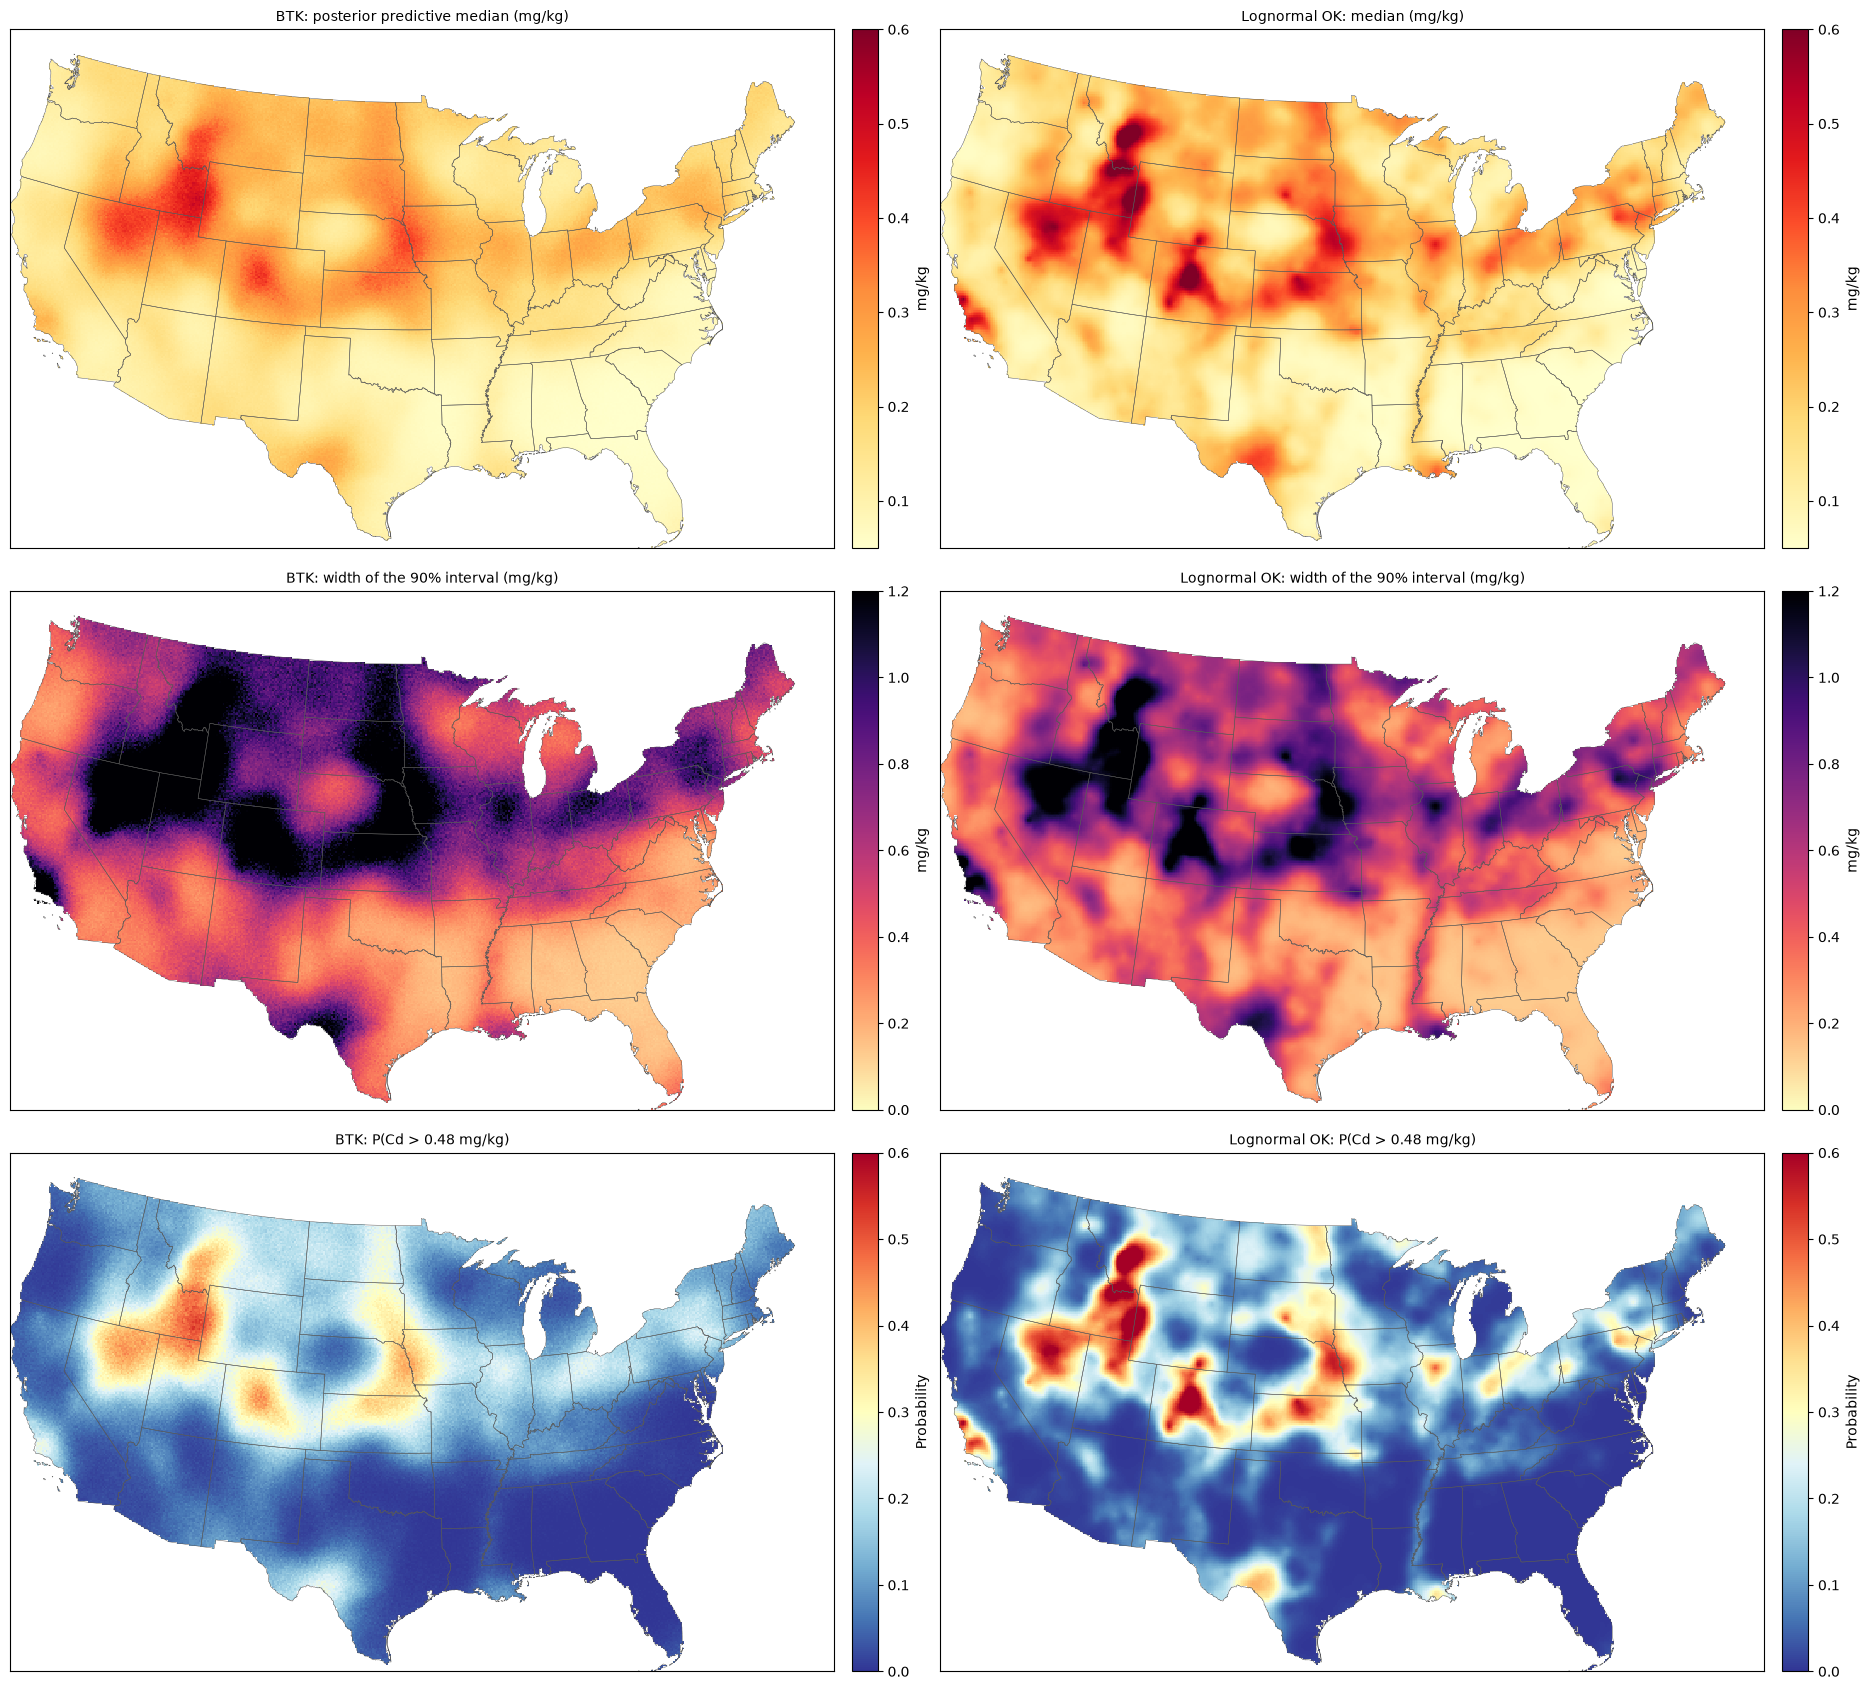

,median_of_medians,mean_P_above_0.48,pct_area_P_above_0.5,mean_90pct_width,share_of_sites_above_0.48_pct
BTK,0.168,0.123,0.122,0.673,10.721
Lognormal OK,0.178,0.118,2.581,0.517,10.721


Correlation of the two median maps: 0.96;  of the two probability maps: 0.93


In [12]:
# Median, 90% interval, and exceedance probabilities, reduced in chunks.
def summarize_draws(draws, thresholds=(THRESHOLD, ECO_SSL["mammalian"], ECO_SSL["avian"])):
    out = {"median": np.empty(draws.shape[1]), "q05": np.empty(draws.shape[1]), "q95": np.empty(draws.shape[1])}
    for t in thresholds:
        out[f"P>{t}"] = np.empty(draws.shape[1])
    for i in range(0, draws.shape[1], CHUNK):
        d = draws[:, i:i + CHUNK]
        out["q05"][i:i + CHUNK], out["median"][i:i + CHUNK], out["q95"][i:i + CHUNK] = np.quantile(d, [0.05, 0.5, 0.95], axis=0)
        for t in thresholds:
            out[f"P>{t}"][i:i + CHUNK] = (d > t).mean(axis=0)
    return out

btk = summarize_draws(btk_draws)
# Lognormal ordinary kriging on the same grid: median exp(mean), 90% limits at 1.645 standard errors.
ok_med = np.exp(fk_total)
ok_q05, ok_q95 = np.exp(fk_total - 1.645 * fk_sd), np.exp(fk_total + 1.645 * fk_sd)
ok_p = {t: 1 - norm.cdf((np.log(t) - fk_total) / fk_sd) for t in (THRESHOLD, ECO_SSL["mammalian"], ECO_SSL["avian"])}

# Median, width of the 90% interval, and P(Cd > 0.48), for BTK and for lognormal OK.
fig, axes = plt.subplots(3, 2, figsize=(19, 17))
plot_grid(axes[0, 0], btk["median"], "BTK: posterior predictive median (mg/kg)", cmap="YlOrRd", vmin=0.05, vmax=0.6, label="mg/kg")
plot_grid(axes[0, 1], ok_med, "Lognormal OK: median (mg/kg)", cmap="YlOrRd", vmin=0.05, vmax=0.6, label="mg/kg")
plot_grid(axes[1, 0], btk["q95"] - btk["q05"], "BTK: width of the 90% interval (mg/kg)", cmap="magma_r", vmin=0, vmax=1.2, label="mg/kg")
plot_grid(axes[1, 1], ok_q95 - ok_q05, "Lognormal OK: width of the 90% interval (mg/kg)", cmap="magma_r", vmin=0, vmax=1.2, label="mg/kg")
plot_grid(axes[2, 0], btk[f"P>{THRESHOLD}"], f"BTK: P(Cd > {THRESHOLD} mg/kg)", cmap="RdYlBu_r", vmin=0, vmax=0.6, label="Probability")
plot_grid(axes[2, 1], ok_p[THRESHOLD], f"Lognormal OK: P(Cd > {THRESHOLD} mg/kg)", cmap="RdYlBu_r", vmin=0, vmax=0.6, label="Probability")
plt.tight_layout()
plt.show()

# National summaries. The site share is the percentage of sample sites above 0.48 mg/kg.
cmp_tbl = pd.DataFrame({
    "BTK": {"median_of_medians": np.median(btk["median"]), "mean_P_above_0.48": btk[f"P>{THRESHOLD}"].mean(),
            "pct_area_P_above_0.5": 100 * np.mean(btk[f"P>{THRESHOLD}"] > 0.5), "mean_90pct_width": np.mean(btk["q95"] - btk["q05"])},
    "Lognormal OK": {"median_of_medians": np.median(ok_med), "mean_P_above_0.48": ok_p[THRESHOLD].mean(),
                     "pct_area_P_above_0.5": 100 * np.mean(ok_p[THRESHOLD] > 0.5), "mean_90pct_width": np.mean(ok_q95 - ok_q05)},
}).T
cmp_tbl["share_of_sites_above_0.48_pct"] = 100 * np.mean(cd > THRESHOLD)
display(cmp_tbl.round(3))
print(f"Correlation of the two median maps: {np.corrcoef(np.log(btk['median']), fk_total)[0, 1]:.2f};  "
      f"of the two probability maps: {np.corrcoef(btk[f'P>{THRESHOLD}'], ok_p[THRESHOLD])[0, 1]:.2f}")

**Reading the results.**

- **The Box-Cox parameter is between −0.25 and 0.** Four of the six partitions put most of the posterior mass on λ = −0.25 and two on λ = 0 (the log). The pooled mean is −0.17. A slightly stronger transform than the log is preferred, which compresses the upper tail more.
- **The range and nugget differ between partitions.** The posterior median range varies from 320 to 980 km, and the nugget ratio from 0.5 to 1.0. This is the parameter uncertainty that BTK carries into its predictions, and that kriging with a fixed variogram leaves out.
- **The two medians agree but BTK is smoother.** The median maps of BTK and lognormal OK correlate at 0.96. Each BTK partition sees only 800 sites, so it cannot resolve the local highs that OK shows in Idaho, Colorado and Nebraska.
- **BTK intervals are wider.** The mean width of its 90% interval is 0.67 mg/kg against 0.52 for OK, and the widest intervals are where Cd is highest.
- **Exceedance is rarely more likely than not.** Both methods put the expected share of area above 0.48 mg/kg at about 12%, close to the 10.7% of sites. Because of the large nugget, the probability rarely exceeds 0.5: on 0.1% of the area for BTK and 2.6% for OK. The probability maps should be read as relative risk, highest across the northern Rockies and the northern Plains.

## Spatially blocked cross-validation

The sites are grouped into 300 km squares, which is longer than the local range, and the squares are assigned at random to 10 folds. Each fold is predicted from the other nine with three methods:

- **Lognormal OK**: ordinary kriging of log Cd with the nested variogram refitted to the training sites (`FactorialKriging.extract("total")`).
- **BTK ensemble**: the partitioned Bayesian transformed kriging of Section 6, refitted to the training sites.
- **Lognormal OK, all-data variogram**: the same as the first method but with the variogram from all sites. It shows how much refitting the variogram matters.

The scores are on log Cd (RMSE, bias and the continuous ranked probability score, CRPS) and on the decision (Brier score and AUC for Cd > 0.48 mg/kg, and the coverage of the 50% and 90% prediction intervals). Censored sites enter with their substituted value of 0.05 mg/kg, which is below the threshold under every treatment.

In [13]:
# Blocks of 300 km. Each whole block is assigned to one of ten folds.
BLOCK_KM = 300
block_id = np.unique(np.floor(xy / BLOCK_KM).astype(int), axis=0, return_inverse=True)[1].ravel()
fold_of_block = np.random.default_rng(SEED).integers(0, 10, block_id.max() + 1)
fold = fold_of_block[block_id]
print(f"{block_id.max() + 1} blocks of {BLOCK_KM} km; sites per fold: {np.bincount(fold).tolist()}")

# Continuous ranked probability score of a Gaussian forecast, on the log scale.
def crps_gaussian(y, mu, sd):
    zz = (y - mu) / sd
    return sd * (zz * (2 * norm.cdf(zz) - 1) + 2 * norm.pdf(zz) - 1 / np.sqrt(np.pi))

def crps_sample(y, draws):
    # Energy form, using the sorted-sample identity for E|X - X'|
    x = np.sort(draws, axis=0)
    n = x.shape[0]
    term1 = np.mean(np.abs(x - y[None, :]), axis=0)
    w = (2 * np.arange(1, n + 1) - n - 1)[:, None]
    term2 = np.sum(w * x, axis=0) / n ** 2
    return term1 - term2

# Kriging mean, 50% and 90% intervals, exceedance probability, and CRPS, filled fold by fold.
res = {m: {"mu": np.empty(len(z)), "lo50": np.empty(len(z)), "hi50": np.empty(len(z)), "lo90": np.empty(len(z)),
           "hi90": np.empty(len(z)), "p": np.empty(len(z)), "crps": np.empty(len(z))} for m in ["Lognormal OK", "Lognormal OK, all-data variogram", "BTK ensemble"]}
t0 = time.perf_counter()
for f in range(10):
    te, tr = np.flatnonzero(fold == f), np.flatnonzero(fold != f)
# Two ordinary-kriging scores: variogram refit on the training blocks, and the all-sites variogram.
    for name, (nug, st) in [("Lognormal OK", fit_nested_variogram(xy[tr], z[tr], models=("spherical",) * 3, n_lags=N_LAGS, maxlag=MAXLAG)[:2]),
                            ("Lognormal OK, all-data variogram", (NUG, STRUCTS))]:
        m, v = FactorialKriging(nug, st, max_neighbors=FK_NEIGHBORS, use_gpu=USE_GPU).fit(xy[tr], z[tr]).extract(xy[te], "total", return_variance=True)
        s = np.sqrt(np.maximum(v, 1e-12))
        r = res[name]
        r["mu"][te] = m
        r["lo50"][te], r["hi50"][te] = m - 0.674 * s, m + 0.674 * s
        r["lo90"][te], r["hi90"][te] = m - 1.645 * s, m + 1.645 * s
        r["p"][te] = 1 - norm.cdf((np.log(THRESHOLD) - m) / s)
        r["crps"][te] = crps_gaussian(z[te], m, s)
# Bayesian transformed kriging on the same training sites, scored on the log of its draws.
    dr, _ = btk_ensemble(tr, xy[te], seed=SEED + f)
    ld = np.log(dr.astype(float))
    r = res["BTK ensemble"]
    r["mu"][te] = np.median(ld, axis=0)
    r["lo50"][te], r["hi50"][te], r["lo90"][te], r["hi90"][te] = np.quantile(ld, [0.25, 0.75, 0.05, 0.95], axis=0)
    r["p"][te] = (dr > THRESHOLD).mean(axis=0)
    r["crps"][te] = crps_sample(z[te], ld)
print(f"Blocked cross-validation: {(time.perf_counter() - t0) / 60:.1f} min")

# RMSE, interval coverage, and the Brier score and AUC of P(Cd > 0.48).
y_exc = (cd > THRESHOLD).astype(int)
cv_tbl = pd.DataFrame({name: {
    "RMSE_log": np.sqrt(np.mean((r["mu"] - z) ** 2)), "bias_log": np.mean(r["mu"] - z), "CRPS_log": r["crps"].mean(),
    "cover_50_pct": 100 * np.mean((z >= r["lo50"]) & (z <= r["hi50"])), "cover_90_pct": 100 * np.mean((z >= r["lo90"]) & (z <= r["hi90"])),
    "Brier_0.48": brier_score_loss(y_exc, np.clip(r["p"], 0, 1)), "AUC_0.48": roc_auc_score(y_exc, r["p"]),
    "mean_P_0.48": r["p"].mean()} for name, r in res.items()}).T
cv_tbl.loc["No skill (site proportion)", ["Brier_0.48", "mean_P_0.48"]] = [y_exc.mean() * (1 - y_exc.mean()), y_exc.mean()]
display(cv_tbl.round(3))
print(f"Observed share of sites above {THRESHOLD} mg/kg: {y_exc.mean():.3f}")

111 blocks of 300 km; sites per fold: [437, 491, 311, 405, 712, 254, 586, 741, 506, 370]


Blocked cross-validation: 2.4 min


,RMSE_log,bias_log,CRPS_log,cover_50_pct,cover_90_pct,Brier_0.48,AUC_0.48,mean_P_0.48
Lognormal OK,0.696,0.011,0.384,53.750,90.796,0.086,0.763,0.124
"Lognormal OK, all-data variogram",0.695,0.012,0.384,54.124,91.004,0.086,0.765,0.125
BTK ensemble,0.720,-0.038,0.399,54.498,91.980,0.088,0.746,0.126
No skill (site proportion),NaN,NaN,NaN,NaN,NaN,0.096,NaN,0.107


Observed share of sites above 0.48 mg/kg: 0.107


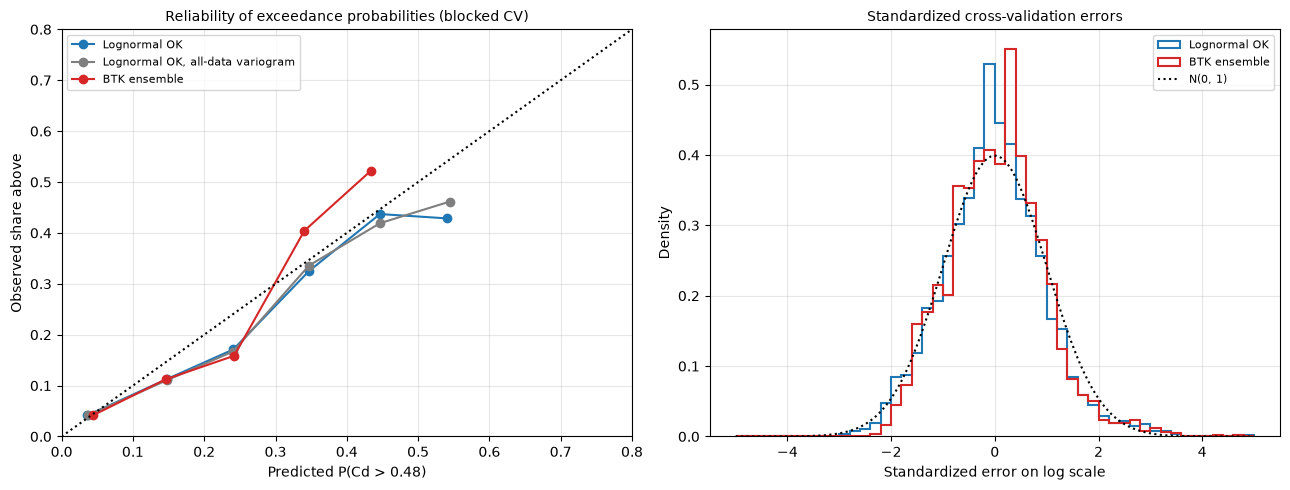

In [14]:
# Reliability diagram. Bins with fewer than 20 sites are left out.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = np.linspace(0, 1, 11)
for name, c in zip(res, ["tab:blue", "tab:gray", "tab:red"]):
    p = np.clip(res[name]["p"], 0, 1)
    b = np.clip(np.digitize(p, bins) - 1, 0, 9)
    px = [p[b == k].mean() for k in range(10) if np.sum(b == k) >= 20]
    py = [y_exc[b == k].mean() for k in range(10) if np.sum(b == k) >= 20]
    axes[0].plot(px, py, "o-", color=c, label=name)
# Dotted line: predicted probability equal to the observed share.
axes[0].plot([0, 1], [0, 1], "k:")
axes[0].set_xlim(0, 0.8); axes[0].set_ylim(0, 0.8)
axes[0].set_xlabel(f"Predicted P(Cd > {THRESHOLD})"); axes[0].set_ylabel("Observed share above")
axes[0].set_title("Reliability of exceedance probabilities (blocked CV)", fontsize=10)
axes[0].legend(fontsize=8)
# Standardized error. Interval width is turned back into a standard deviation with the factor 1.645.
for name, c in zip(["Lognormal OK", "BTK ensemble"], ["tab:blue", "tab:red"]):
    r = res[name]
    zs = (z - r["mu"]) / ((r["hi90"] - r["lo90"]) / (2 * 1.645))
    axes[1].hist(zs, bins=50, range=(-5, 5), histtype="step", lw=1.5, color=c, density=True, label=name)
# Standard normal, the shape expected when the predictive intervals are well calibrated.
xx = np.linspace(-5, 5, 200)
axes[1].plot(xx, norm.pdf(xx), "k:", label="N(0, 1)")
axes[1].set_xlabel("Standardized error on log scale"); axes[1].set_ylabel("Density")
axes[1].set_title("Standardized cross-validation errors", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading the results.**

- **Lognormal OK predicts new areas slightly better.** Its CRPS is 0.384 against 0.399 for the BTK ensemble, its RMSE of log Cd 0.70 against 0.72, and its AUC at 0.48 mg/kg 0.76 against 0.75. The difference is small, and it is the price of fitting BTK on partitions of 800 sites. A BTK fitted to all sites would close it, but that is not possible with the memory available.
- **Refitting the variogram in each fold makes no difference.** The scores with the all-data variogram are identical to the third decimal, so the nested model is stable.
- **Both methods give honest intervals.** The 90% intervals cover 91% (OK) and 92% (BTK) of held-out sites, and the 50% intervals 54%. The standardized errors are close to a standard normal.
- **Both methods are overconfident at the high end.** Brier scores are 0.086 and 0.088 against 0.096 for no skill, about a 10% improvement. Sites given a probability of 0.45 to 0.55 by OK exceed the threshold only 43% of the time. BTK is better calibrated above 0.3, where its observed shares match or exceed the predicted probability.

Overall, neither method can say with confidence whether a particular new site exceeds 0.48 mg/kg, but both rank areas well and their intervals can be trusted.

## Area above the screening value by region and state

Each grid node represents 100 km². The expected area above a threshold in a region is the sum of the exceedance probabilities times the cell area. The area where the probability exceeds 0.5 is the area that would be delineated as "more likely than not above". Both are reported for 0.48 mg/kg and for the two Eco-SSLs.

By Census region:


,area_1000km2,BTK_median_mg_kg,expected_pct_above_0.48,pct_area_P048_gt_0.5,OK_expected_pct_above_0.48,expected_pct_above_0.36,expected_pct_above_0.77,sites,site_pct_above_0.48
REGION,,,,,,,,,
Midwest,1984.0,0.2,17.4,0.0,16.7,27.0,7.5,1233,12.7
West,3074.5,0.2,15.8,0.3,15.2,24.1,7.1,1903,13.8
Northeast,435.4,0.2,13.3,0.0,12.5,21.7,5.3,260,14.6
South,2314.0,0.1,3.2,0.0,3.1,5.9,1.1,1417,4.2


Ten states with the highest expected share of area above 0.48 mg/kg:


,area_1000km2,BTK_median_mg_kg,expected_pct_above_0.48,pct_area_P048_gt_0.5,OK_expected_pct_above_0.48,expected_pct_above_0.36,expected_pct_above_0.77,sites,site_pct_above_0.48
STATE,,,,,,,,,
Idaho,216.8,0.3,27.6,4.2,26.8,38.9,14.0,132.0,23.5
Colorado,269.4,0.3,25.8,0.0,28.1,37.8,12.3,165.0,25.5
Iowa,146.5,0.3,25.2,0.0,23.5,37.3,11.4,91.0,17.6
Nevada,285.5,0.3,23.8,0.0,25.5,34.5,11.6,174.0,27.0
Kansas,214.6,0.3,23.4,0.0,26.7,34.9,10.6,127.0,18.9
Wyoming,253.4,0.3,23.3,0.2,20.9,34.7,10.5,161.0,18.6
Montana,381.0,0.2,22.8,0.0,21.5,34.0,10.5,239.0,16.3
South Dakota,199.2,0.3,22.6,0.0,23.6,34.1,10.2,120.0,14.2
North Dakota,182.9,0.3,21.8,0.0,19.9,33.3,9.5,118.0,7.6


Conterminous USA: {'expected_pct_above_0.48': np.float64(12.3), 'pct_area_P048_gt_0.5': np.float64(0.1), 'expected_pct_above_0.36': np.float64(19.3), 'expected_pct_above_0.77': np.float64(5.3)}


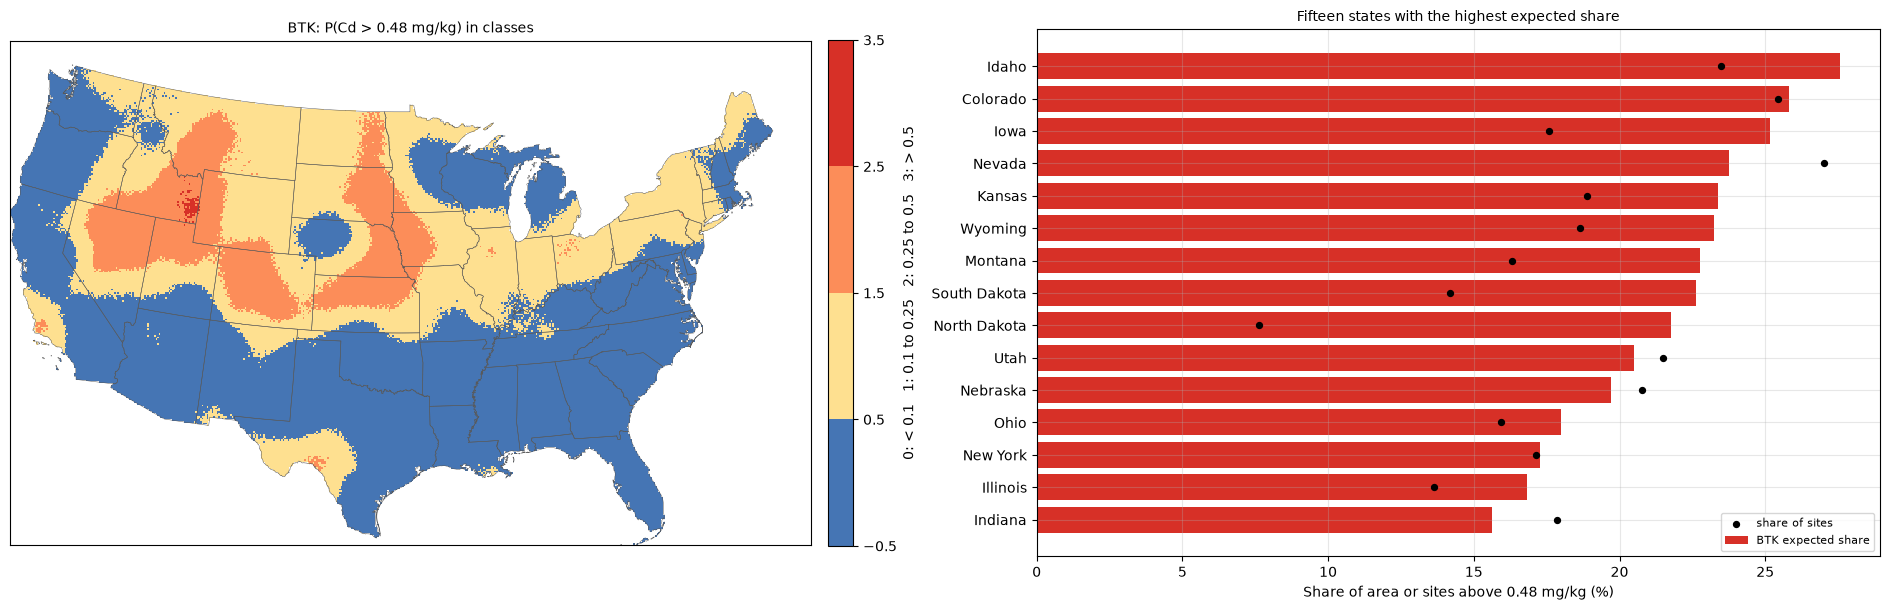

In [15]:
# One row per grid node: region, state, BTK probabilities, the OK probability, and the BTK median.
reg = pd.DataFrame({"REGION": grid["REGION"].to_numpy(), "STATE": grid["STATE"].to_numpy(),
                    "P048": btk[f"P>{THRESHOLD}"], "P036": btk[f"P>{ECO_SSL['mammalian']}"], "P077": btk[f"P>{ECO_SSL['avian']}"],
                    "OK_P048": ok_p[THRESHOLD], "median": btk["median"]})

# Expected exceedance is the mean probability. The half-probability column is the share of area above that chance.
def area_summary(by):
    g = reg.groupby(by)
    out = pd.DataFrame({
        "area_1000km2": g.size() * CELL_KM2 / 1000,
        "BTK_median_mg_kg": g["median"].median(),
        "expected_pct_above_0.48": 100 * g["P048"].mean(),
        "pct_area_P048_gt_0.5": 100 * g["P048"].apply(lambda s: np.mean(s > 0.5)),
        "OK_expected_pct_above_0.48": 100 * g["OK_P048"].mean(),
        "expected_pct_above_0.36": 100 * g["P036"].mean(),
        "expected_pct_above_0.77": 100 * g["P077"].mean(),
    })
    sites_g = data.groupby(by)["Cd"]
    out["sites"] = sites_g.size()
    out["site_pct_above_0.48"] = sites_g.apply(lambda s: 100 * np.mean(s > THRESHOLD))
    return out

# Census regions, then the states with the largest expected share above 0.48 mg/kg.
print("By Census region:")
display(area_summary("REGION").sort_values("expected_pct_above_0.48", ascending=False).round(1))
state_tbl = area_summary("STATE").sort_values("expected_pct_above_0.48", ascending=False)
print("Ten states with the highest expected share of area above 0.48 mg/kg:")
display(state_tbl.head(10).round(1))
nat = {"expected_pct_above_0.48": 100 * reg["P048"].mean(), "pct_area_P048_gt_0.5": 100 * np.mean(reg["P048"] > 0.5),
       "expected_pct_above_0.36": 100 * reg["P036"].mean(), "expected_pct_above_0.77": 100 * reg["P077"].mean()}
print("Conterminous USA:", {k: round(v, 1) for k, v in nat.items()})

# Classed probability map, and the fifteen highest states with the site exceedance rate as points.
fig, axes = plt.subplots(1, 2, figsize=(19, 6.2))
pcls = np.digitize(btk[f"P>{THRESHOLD}"], [0.1, 0.25, 0.5])
plot_grid(axes[0], pcls, f"BTK: P(Cd > {THRESHOLD} mg/kg) in classes", cmap=ListedColormap(["#4575b4", "#fee090", "#fc8d59", "#d73027"]),
          norm_=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4), label="0: < 0.1   1: 0.1 to 0.25   2: 0.25 to 0.5   3: > 0.5")
top10 = state_tbl.head(15).iloc[::-1]
axes[1].barh(top10.index, top10["expected_pct_above_0.48"], color="#d73027", label="BTK expected share")
axes[1].scatter(top10["site_pct_above_0.48"], top10.index, color="k", s=18, zorder=3, label="share of sites")
axes[1].set_xlabel(f"Share of area or sites above {THRESHOLD} mg/kg (%)")
axes[1].set_title("Fifteen states with the highest expected share", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading the results.**

- **Regions.** The Midwest has the largest expected share of area above 0.48 mg/kg (17%), followed by the West (16%) and the Northeast (13%). The South has 3%. The same order holds for the two Eco-SSLs. Nationally, about 19% of the area is expected to exceed 0.36 mg/kg and 5% to exceed 0.77 mg/kg.
- **States.** The highest expected shares are in Idaho (28%), Colorado (26%), Iowa (25%), Nevada, Kansas and Wyoming (about 23% to 24%), then Montana and the Dakotas. Only Idaho has a noticeable area (4%) where exceedance is more likely than not.
- **Mapped and sampled shares differ.** In North Dakota the expected share (22%) is about three times the share of sites (8%). The kriged surface borrows from high values in neighbouring states, so state figures near high-Cd regions should be read together with the site counts.

The expected share is the more useful of the two area measures here. It sums the probabilities over each region, so it remains informative when no individual cell is likely to exceed the threshold.

## Summary of results

In [16]:
# Method with the lowest CRPS on the log scale in the blocked cross-validation.
best = cv_tbl.drop(index="No skill (site proportion)")["CRPS_log"].idxmin()
summary = pd.DataFrame([
    ("Sites with Cd", f"{len(z):,} ({100 * c_obs.mean():.1f}% below {DL} mg/kg)"),
    ("Share of sites above 0.48 mg/kg", f"{100 * np.mean(cd > THRESHOLD):.1f}%"),
    ("Nested model (3 spherical structures)", f"nugget {nest_tbl.loc[3, 'nugget_share_pct']:.0f}%, "
     f"{STRUCTS[0]['range']:.0f} km {nest_tbl.loc[3, 'share_1_pct']:.0f}%, {STRUCTS[1]['range']:.0f} km {nest_tbl.loc[3, 'share_2_pct']:.0f}%, "
     f"{STRUCTS[2]['range']:.0f} km {nest_tbl.loc[3, 'share_3_pct']:.0f}% of the sill"),
# Structural correlations, then the blocked cross-validation scores.
    ("Structural correlation of Cd with Zn (local / regional)", f"{struct_corr.loc['Zn', names[1]]:.2f} / {struct_corr.loc['Zn', names[2]]:.2f}"),
    ("Structural correlation of Cd with P (local / regional)", f"{struct_corr.loc['P', names[1]]:.2f} / {struct_corr.loc['P', names[2]]:.2f}"),
    ("Posterior Box-Cox lambda (mean over partitions)", f"{btk_params['lambda'].mean():.2f}"),
    ("Blocked CV CRPS (log), OK / BTK", f"{cv_tbl.loc['Lognormal OK', 'CRPS_log']:.3f} / {cv_tbl.loc['BTK ensemble', 'CRPS_log']:.3f}"),
    ("Blocked CV 90% coverage, OK / BTK", f"{cv_tbl.loc['Lognormal OK', 'cover_90_pct']:.0f}% / {cv_tbl.loc['BTK ensemble', 'cover_90_pct']:.0f}%"),
    ("Blocked CV AUC at 0.48, OK / BTK", f"{cv_tbl.loc['Lognormal OK', 'AUC_0.48']:.2f} / {cv_tbl.loc['BTK ensemble', 'AUC_0.48']:.2f}"),
# Mapped area above the screening value and above the two Eco-SSLs.
    ("Expected share of area above 0.48 mg/kg (BTK)", f"{nat['expected_pct_above_0.48']:.1f}%"),
    ("Area where P(Cd > 0.48) > 0.5 (BTK)", f"{nat['pct_area_P048_gt_0.5']:.1f}%"),
    ("Expected share above Eco-SSLs 0.36 / 0.77 mg/kg", f"{nat['expected_pct_above_0.36']:.1f}% / {nat['expected_pct_above_0.77']:.1f}%"),
    ("Region with the highest expected share", area_summary("REGION")["expected_pct_above_0.48"].idxmax()),
], columns=["Result", "Value"])
display(summary)

,Result,Value
0,Sites with Cd,"4,813 (23.8% below 0.1 mg/kg)"
1,Share of sites above 0.48 mg/kg,10.7%
2,Nested model (3 spherical structures),"nugget 33%, 239 km 9%, 761 km 17%, 7500 km 42% of the sill"
3,Structural correlation of Cd with Zn (local / regional),0.94 / 0.76
4,Structural correlation of Cd with P (local / regional),0.64 / 0.96
5,Posterior Box-Cox lambda (mean over partitions),-0.17
6,"Blocked CV CRPS (log), OK / BTK",0.384 / 0.399
7,"Blocked CV 90% coverage, OK / BTK",91% / 92%
8,"Blocked CV AUC at 0.48, OK / BTK",0.76 / 0.75
9,Expected share of area above 0.48 mg/kg (BTK),12.3%


## Conclusions and limitations

**What the analysis shows**

1. About 11% of sites, and an expected 12% of the area of the conterminous USA, exceed 0.48 mg/kg Cd in the A horizon. The share is highest in the Midwest and the West and lowest in the South.
2. Cd varies at three scales: a large nugget (33% of the sill), a local structure of about 240 km (9%), a regional structure of about 760 km (17%) and a continental trend (about 40%).
3. At the local scale Cd follows Zn (structural correlation 0.94), which points to geology and mineralization. At the regional scale it follows P (0.96). No land-cover signal appears at either scale, so any fertilizer effect is confined to field scale.
4. The posterior of the Box-Cox parameter favours a transform slightly stronger than the log (λ about −0.17). Bayesian transformed kriging gives wider and somewhat better-calibrated intervals, but lognormal OK on all sites predicts new areas slightly better than the partitioned BTK ensemble.
5. Because a third of the variance is nugget, the probability of exceeding 0.48 mg/kg is rarely above 0.5. The maps identify regions of higher risk; they do not clear or condemn individual fields.

**Limitations**

- The screening value of 0.48 mg/kg was specified for this capstone, but I could not find it in the EPA documents checked; the EPA Eco-SSLs (0.36 and 0.77 mg/kg) are reported alongside it. Cd is reported in steps of 0.1 mg/kg, so the threshold is effectively 0.5 mg/kg.
- Censored values are substituted (DL/2) in all models. A censoring-aware likelihood would be better (Exercise 1).
- BTK is fitted on six partitions of about 800 sites because of memory limits, which loses local detail. Lognormal OK uses all sites.
- The continental structure has no definite range. It is treated as part of the long-range factor, and it cannot be separated from the regional factor within a 300-site neighbourhood.
- The A horizon was sampled to depths of 0.5 to 100 cm. This mixes surface-enriched and deeper soil and inflates the nugget.
- The maps are point predictions for sites, not averages over 10 km cells, and they describe the period 2007 to 2011.
- Exceedance areas are sums of marginal probabilities. Their uncertainty would require joint simulation.

## Exercises

1. Replace the substitution of censored values in BTK with data augmentation: in each partition, draw the censored values from the predictive distribution truncated at 0.1 mg/kg, refit, and repeat. How much do the posterior of λ and the probability map change?
2. Fit `EmpiricalBayesianKriging` on the same partitions as BTK and add it to the cross-validation table. (A single fit to all sites was too slow to include here.)
3. Fit a linear model of coregionalization for log Cd and log Zn with the three ranges of Section 4, and use cokriging to map Cd. Does Zn improve the blocked cross-validation?
4. Repeat Section 5 with land cover as a categorical drift. Does the local factor on cultivated land disappear once the drift is removed?
5. Change the threshold to the 95th percentile of the declustered site distribution and compare the delineated area with that at 0.48 mg/kg.
6. Restrict the analysis to sites sampled at 0 to 20 cm or less. Does the variogram nugget fall?

## References

- De Oliveira, V., Kedem, B. and Short, D. A. (1997). Bayesian prediction of transformed Gaussian random fields. *Journal of the American Statistical Association*, 92, 1422-1433.
- Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation.* Oxford University Press.
- Gneiting, T. and Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association*, 102, 359-378.
- Helsel, D. R. (2012). *Statistics for Censored Environmental Data Using Minitab and R*, 2nd ed. Wiley.
- Smith, D. B., Cannon, W. F., Woodruff, L. G., Solano, F., Kilburn, J. E. and Fey, D. L. (2013). *Geochemical and mineralogical data for soils of the conterminous United States.* U.S. Geological Survey Data Series 801.
- U.S. EPA (2005). *Ecological Soil Screening Levels for Cadmium, Interim Final.* OSWER Directive 9285.7-65.
- Wackernagel, H. (2003). *Multivariate Geostatistics*, 3rd ed. Springer.